# Proyek Portofolio Kualitas Udara: Forensic Environmental Analytics & Dual Machine Learning Pipeline

**Penulis:** Fauzi Asyabani  
**Portofolio:** [portfolio.web.id](https://fauziasyabani.portfolio.web.id)  
**Peran Teknis:** Senior Data Scientist & Machine Learning Engineer  
**Standar Rekayasa:** Google & Kaggle Professional Engineering Standard  
**Dataset:** Saudi Arabia Urban Air Quality Monitoring Dataset (`srisyra02/air-quality-dataset`)

---

## Ringkasan Eksekutif

Polusi udara merupakan salah satu tantangan lingkungan dan kesehatan masyarakat perkotaan paling kritis di era modern. Partikel mikroskopis seperti Particulate Matter (PM2.5 dan PM10), bersama dengan gas beracun seperti Nitrogen Oksida (NOx, NO2), Belerang Dioksida (SO2), Karbon Monoksida (CO), serta senyawa organik volatil (VOCs), memiliki dinamika kimia atmosfer yang saling terkait erat dengan fluktuasi termal lingkungan.

Tujuan utama dari notebook analitis ini adalah:
1. **Audit Kualitas & Integritas Data**: Melakukan forensik kualitas data terhadap sinyal multi-sensor, mengidentifikasi noise kalibrasi instrumen, dan menerapkan transformasi matematis non-negatif.
2. **Exploratory Data Analysis (EDA) Multivariat**: Mengungkap korelasi tersembunyi antara parameter pembakaran bahan bakar (CO, CO2, NOx) dengan pembentukan partikulat sekunder.
3. **Rekayasa Fitur Berbasis Domain Kimia Atmosfer**: Membangun rasio oksidasi, indikator ketidaksempurnaan pembakaran, dan indeks polusi termal untuk memperkuat daya representasi model.
4. **Dual Machine Learning Modeling**:
   - **Tugas Regresi**: Mengestimasi konsentrasi polutan partikulat berbahaya ($PM_{2.5}$) berbasis sensor gas dan kondisi meteorologi menggunakan benchmarking multi-model (Ridge vs Random Forest vs XGBoost).
   - **Tugas Klasifikasi Multi-Kelas**: Mengklasifikasikan tingkat keparahan risiko kesehatan kualitas udara (*Baik*, *Sedang*, *Tidak Sehat*) dengan Stratified 5-Fold Cross Validation.
5. **Interpretasi Model (XAI)**: Menganalisis Feature Importance untuk menyajikan rekomendasi kebijakan lingkungan berbasis bukti kuantitatif.
6. **Ekspor Aset Portofolio**: Mengotomatisasi penyimpanan seluruh grafik berkualitas publikasi (300 DPI, no-emoji, palet korporat) ke direktori `portfolio_assets/` untuk dokumentasi web portofolio.


---
## Modul 1: Konfigurasi Lingkungan, Rationale Pemilihan Pustaka, & Ingestion Data

### Rationale Arsitektural Pemilihan Pustaka (Library Justification)

Dalam standar rekayasa perangkat lunak dan data science profesional, pemilihan dependensi harus didasarkan pada pertimbangan performa, kompatibilitas ekosistem, dan keandalan matematis:

1. **`pandas` (Python Data Analysis Library)**:
   - *Fungsi*: Abstraksi struktur data tabular berkinerja tinggi melalui objek `DataFrame` dan `Series`.
   - *Alasan Pemilihan*: Menawarkan integrasi mulus dengan backend NumPy, mendukung agregasi terindeks, pemfilteran kolom tervektorisasi, dan manipulasi data yang konsisten.
2. **`numpy` (Numerical Python)**:
   - *Fungsi*: Komputasi array berdimensi banyak ($N$-dimensional arrays) dengan pustaka matematika berbasis C.
   - *Alasan Pemilihan*: Diperlukan untuk komputasi aljabar linear berkecepatan tinggi, manipulasi matriks fitur, serta perhitungan statistik residual yang deterministik.
3. **`matplotlib.pyplot` & `seaborn`**:
   - *Fungsi*: Antarmuka pembuatan grafik statistik tingkat lanjut.
   - *Alasan Pemilihan*: Seaborn menyediakan abstraksi visual statistik tingkat tinggi, sedangkan Matplotlib memberikan kendali tingkat rendah untuk mengatur resolusi kanvas (300 DPI), tipografi, margin bebas whitespace (`bbox_inches='tight'`), dan tata letak multi-panel yang presisi untuk kebutuhan portofolio.
4. **`scikit-learn`**:
   - *Fungsi*: Kerangka kerja standar de-facto untuk machine learning klasik.
   - *Alasan Pemilihan*: Menyediakan implementasi efisien untuk pra-pemrosesan (`StandardScaler`, `LabelEncoder`), algoritma baseline teruji (`Ridge`, `LogisticRegression`, `RandomForest`), validasi silang terstratifikasi (`StratifiedKFold`, `KFold`), serta metrik evaluasi formal (`mean_squared_error`, `classification_report`, `confusion_matrix`).
5. **`xgboost` (Extreme Gradient Boosting)**:
   - *Fungsi*: Implementasi algoritma Gradient Boosted Decision Trees (GBDT) yang dioptimalkan untuk kecepatan dan generalisasi.
   - *Alasan Pemilihan*: Terbukti secara empiris mendominasi kompetisi pemodelan data tabular di Kaggle berkat dukungan regularisasi terintegrasi (L1/L2 shrinkage), penanganan interaksi non-linear yang agresif, dan komputasi paralel pohon keputusan.
6. **`kagglehub`**:
   - *Fungsi*: Utilitas resmi Kaggle Client untuk mengunduh dataset langsung dari Kaggle API secara programmatic.


In [1]:
# Sel 1: Konfigurasi Dependensi dan Penyiapan Lingkungan Komputasi

import os
import sys
import shutil
import warnings
from pathlib import Path

# Pustaka Inti Manipulasi Data dan Komputasi Numerik
import numpy as np
import pandas as pd

# Pustaka Visualisasi Data dan Rendering Kanvas Resolusi Tinggi
import matplotlib.pyplot as plt
import seaborn as sns

# Pustaka Machine Learning: Pra-pemrosesan dan Validasi Model
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Pustaka Algoritma Pemodelan (Baseline, Ensemble, dan Gradient Boosting)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import xgboost as xgb

# Pustaka Data Ingestion
import kagglehub

# Konfigurasi Kebijakan Runtime
warnings.filterwarnings('ignore')
np.random.seed(42)

# Konfigurasi Standar Estetika Matplotlib dan Seaborn untuk Portofolio
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.autolayout'] = False
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16

# Pembuatan Direktori Output untuk Aset Portofolio Web
OUTPUT_DIR = Path('portfolio_assets')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Status Inisialisasi: Lingkungan komputasi, konfigurasi estetika, dan dependensi berhasil dimuat.")


Status Inisialisasi: Lingkungan komputasi, konfigurasi estetika, dan dependensi berhasil dimuat.


### Arsitektur Data Ingestion Hybrid (KaggleHub + Local Cache Fail-safe)

Untuk menjamin prinsip *Reproducibility* dan portabilitas kode di berbagai lingkungan (seperti Google Colab, server lokal, atau kontainer Docker), fungsi ingestion dirancang dengan pola *graceful degradation*:
1. Menguji ketersediaan file dataset lokal di direktori `data/air_quality_dataset.csv`.
2. Jika file lokal tidak ditemukan, mencoba mengunduh versi rilis terbaru secara programmatic via `kagglehub.dataset_download`.
3. Menyimpan cache lokal secara otomatis agar proses komputasi berikutnya tidak memerlukan koneksi jaringan berulang.


In [2]:
# Sel 2: Implementasi Fungsi Ingestion Data Hybrid

def load_air_quality_dataset() -> pd.DataFrame:
    """
    Memuat dataset kualitas udara dengan mekanisme hybrid:
    Memeriksa ketersediaan cache lokal terlebih dahulu, kemudian fallback ke KaggleHub.
    
    Returns:
        pd.DataFrame: Dataframe mentah kualitas udara.
    """
    local_path = Path('data') / 'air_quality_dataset.csv'
    
    if local_path.exists():
        print(f"Menggunakan dataset dari cache lokal: {local_path.resolve()}")
        df_loaded = pd.read_csv(local_path)
        return df_loaded
    
    print("Dataset lokal belum tersedia. Melakukan ingestion melalui KaggleHub API...")
    try:
        download_dir = kagglehub.dataset_download('srisyra02/air-quality-dataset')
        downloaded_file = Path(download_dir) / 'air_quality_dataset.csv'
        
        # Salin ke folder lokal untuk idempotensi eksekusi
        local_path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(downloaded_file, local_path)
        print(f"Dataset berhasil diunduh dan disimpan ke: {local_path.resolve()}")
        return pd.read_csv(local_path)
    except Exception as err:
        raise RuntimeError(
            f"Kegagalan fatal pada proses ingestion data: {str(err)}. "
            "Pastikan file 'air_quality_dataset.csv' tersedia di direktori data/ atau koneksi internet aktif."
        )

# Eksekusi Pemanggilan Data
raw_df = load_air_quality_dataset()
print(f"Dimensi Dataset Mentah: {raw_df.shape[0]} baris dan {raw_df.shape[1]} kolom.")
raw_df.head()


Menggunakan dataset dari cache lokal: D:\Code\air-quality\data\air_quality_dataset.csv
Dimensi Dataset Mentah: 500 baris dan 10 kolom.


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


---
## Modul 2: Audit Integritas Data & Pra-pemrosesan Forensik

Dalam analisis kualitas udara berbasis sensor elektrokimia dan optik, anomali data sering kali muncul akibat keterbatasan fisik instrumen, seperti:
- **Baseline Zero Drift**: Nilai pembacaan sensor menghasilkan angka negatif mendekati nol ketika konsentrasi gas berada di bawah batas ambang deteksi (Limit of Detection / LOD).
- **Saturasi Pembacaan**: Lonjakan konsentrasi ekstrem sesaat yang memerlukan validasi statistik.

Pada tahap ini, kita melakukan audit tipe data, kelengkapan nilai (*missing values*), rentang fisik polutan, serta koreksi matematis yang dapat dipertanggungjawabkan secara saintifik.


In [3]:
# Sel 3: Pemeriksaan Skema, Kelengkapan Nilai, dan Statistik Deskriptif

print("=== Struktur Skema dan Tipe Data Kolom ===")
raw_df.info()

print("\n=== Deteksi Nilai Kosong (Missing Values) ===")
missing_summary = raw_df.isnull().sum()
print(missing_summary)

print("\n=== Statistik Deskriptif Parameter Polutan dan Meteorologi ===")
summary_stats = raw_df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats.round(3)


=== Struktur Skema dan Tipe Data Kolom ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB

=== Deteksi Nilai Kosong (Missing Values) ===
PM2.5          0
PM10           0
NOx            0
NO2            0
SO2            0
VOCs           0
CO             0
CO2            0
CH4            0
Temperature    0
dtype: int64

=== Statistik Deskriptif Parameter Polutan dan Meteorologi ===


,count,mean,std,min,25%,50%,75%,max
PM2.5,500.0,54.672,22.799,10.758,36.373,48.039,73.821,127.617
PM10,500.0,84.703,30.568,12.932,61.119,78.136,110.270,171.594
NOx,500.0,91.814,54.808,-0.076,35.457,95.452,134.709,225.887
NO2,500.0,42.411,26.344,-1.942,17.449,39.212,63.818,115.916
SO2,500.0,11.505,7.307,-1.096,5.976,8.681,17.117,31.942
VOCs,500.0,112.193,39.472,27.556,81.517,104.819,140.588,231.926
CO,500.0,2.178,0.825,0.367,1.537,2.046,2.726,4.799
CO2,500.0,439.288,51.221,366.063,397.400,420.934,490.968,558.924
CH4,500.0,2.130,0.391,1.388,1.837,2.067,2.386,3.352
Temperature,500.0,30.448,2.957,19.581,28.482,30.433,32.615,39.779


### Forensik Anomali Sensor: Nilai Konsentrasi Negatif

Berdasarkan tabel statistik di atas, kolom `NOx` memiliki nilai minimum negatif sebesar `-0.076`. Secara fisik, konsentrasi gas di atmosfer tidak mungkin bernilai negatif. Fenomena ini merupakan karakteristik umum pada sensor kimia ketika terjadi fluktuasi sinyal elektronik (*zero-drift noise*).

**Tindakan Rekayasa Data:**
Menerapkan transformasi *lower clipping* pada ambang batas fisik non-negatif ($x = \max(0.0, x)$). Pendekatan ini menjaga integritas data tanpa mendistorsi distribusi keseluruhan populasi.


In [4]:
# Sel 4: Koreksi Anomali Zero-Drift dan Penyiapan Master DataFrame

df = raw_df.copy()

# Koreksi matematis terhadap nilai negatif pada kolom polutan
pollutant_cols = ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4']
for col in pollutant_cols:
    negative_mask = df[col] < 0
    if negative_mask.any():
        negative_count = negative_mask.sum()
        print(f"Pembersihan: Mengoreksi {negative_count} nilai negatif pada parameter '{col}' ke batas non-negatif 0.0.")
        df[col] = df[col].clip(lower=0.0)

print(f"Pemeriksaan Pasca-Koreksi: Nilai minimum NOx sekarang adalah {df['NOx'].min():.4f}.")


Pembersihan: Mengoreksi 1 nilai negatif pada parameter 'NOx' ke batas non-negatif 0.0.
Pembersihan: Mengoreksi 1 nilai negatif pada parameter 'NO2' ke batas non-negatif 0.0.
Pembersihan: Mengoreksi 2 nilai negatif pada parameter 'SO2' ke batas non-negatif 0.0.
Pemeriksaan Pasca-Koreksi: Nilai minimum NOx sekarang adalah 0.0000.


---
## Modul 3: Exploratory Data Analysis (EDA) & Visualisasi Statistik Tingkat Lanjut

Tahap ini membedah hubungan struktural dan non-linear antar-parameter atmosfer. Setiap visualisasi dirancang dengan resolusi tinggi (300 DPI) dan disimpan otomatis ke direktori `portfolio_assets/` agar siap disajikan dalam portofolio profesional.

### Visualisasi 1: Distribusi Probabilitas dan Uji Asimetri Polutan Utama
Grafik ini memvisualisasikan kurva *Kernel Density Estimation* (KDE) dan histogram untuk polutan partikulat ($PM_{2.5}, PM_{10}$) dan gas pembakaran ($NOx, SO_2, CO, CO_2$).


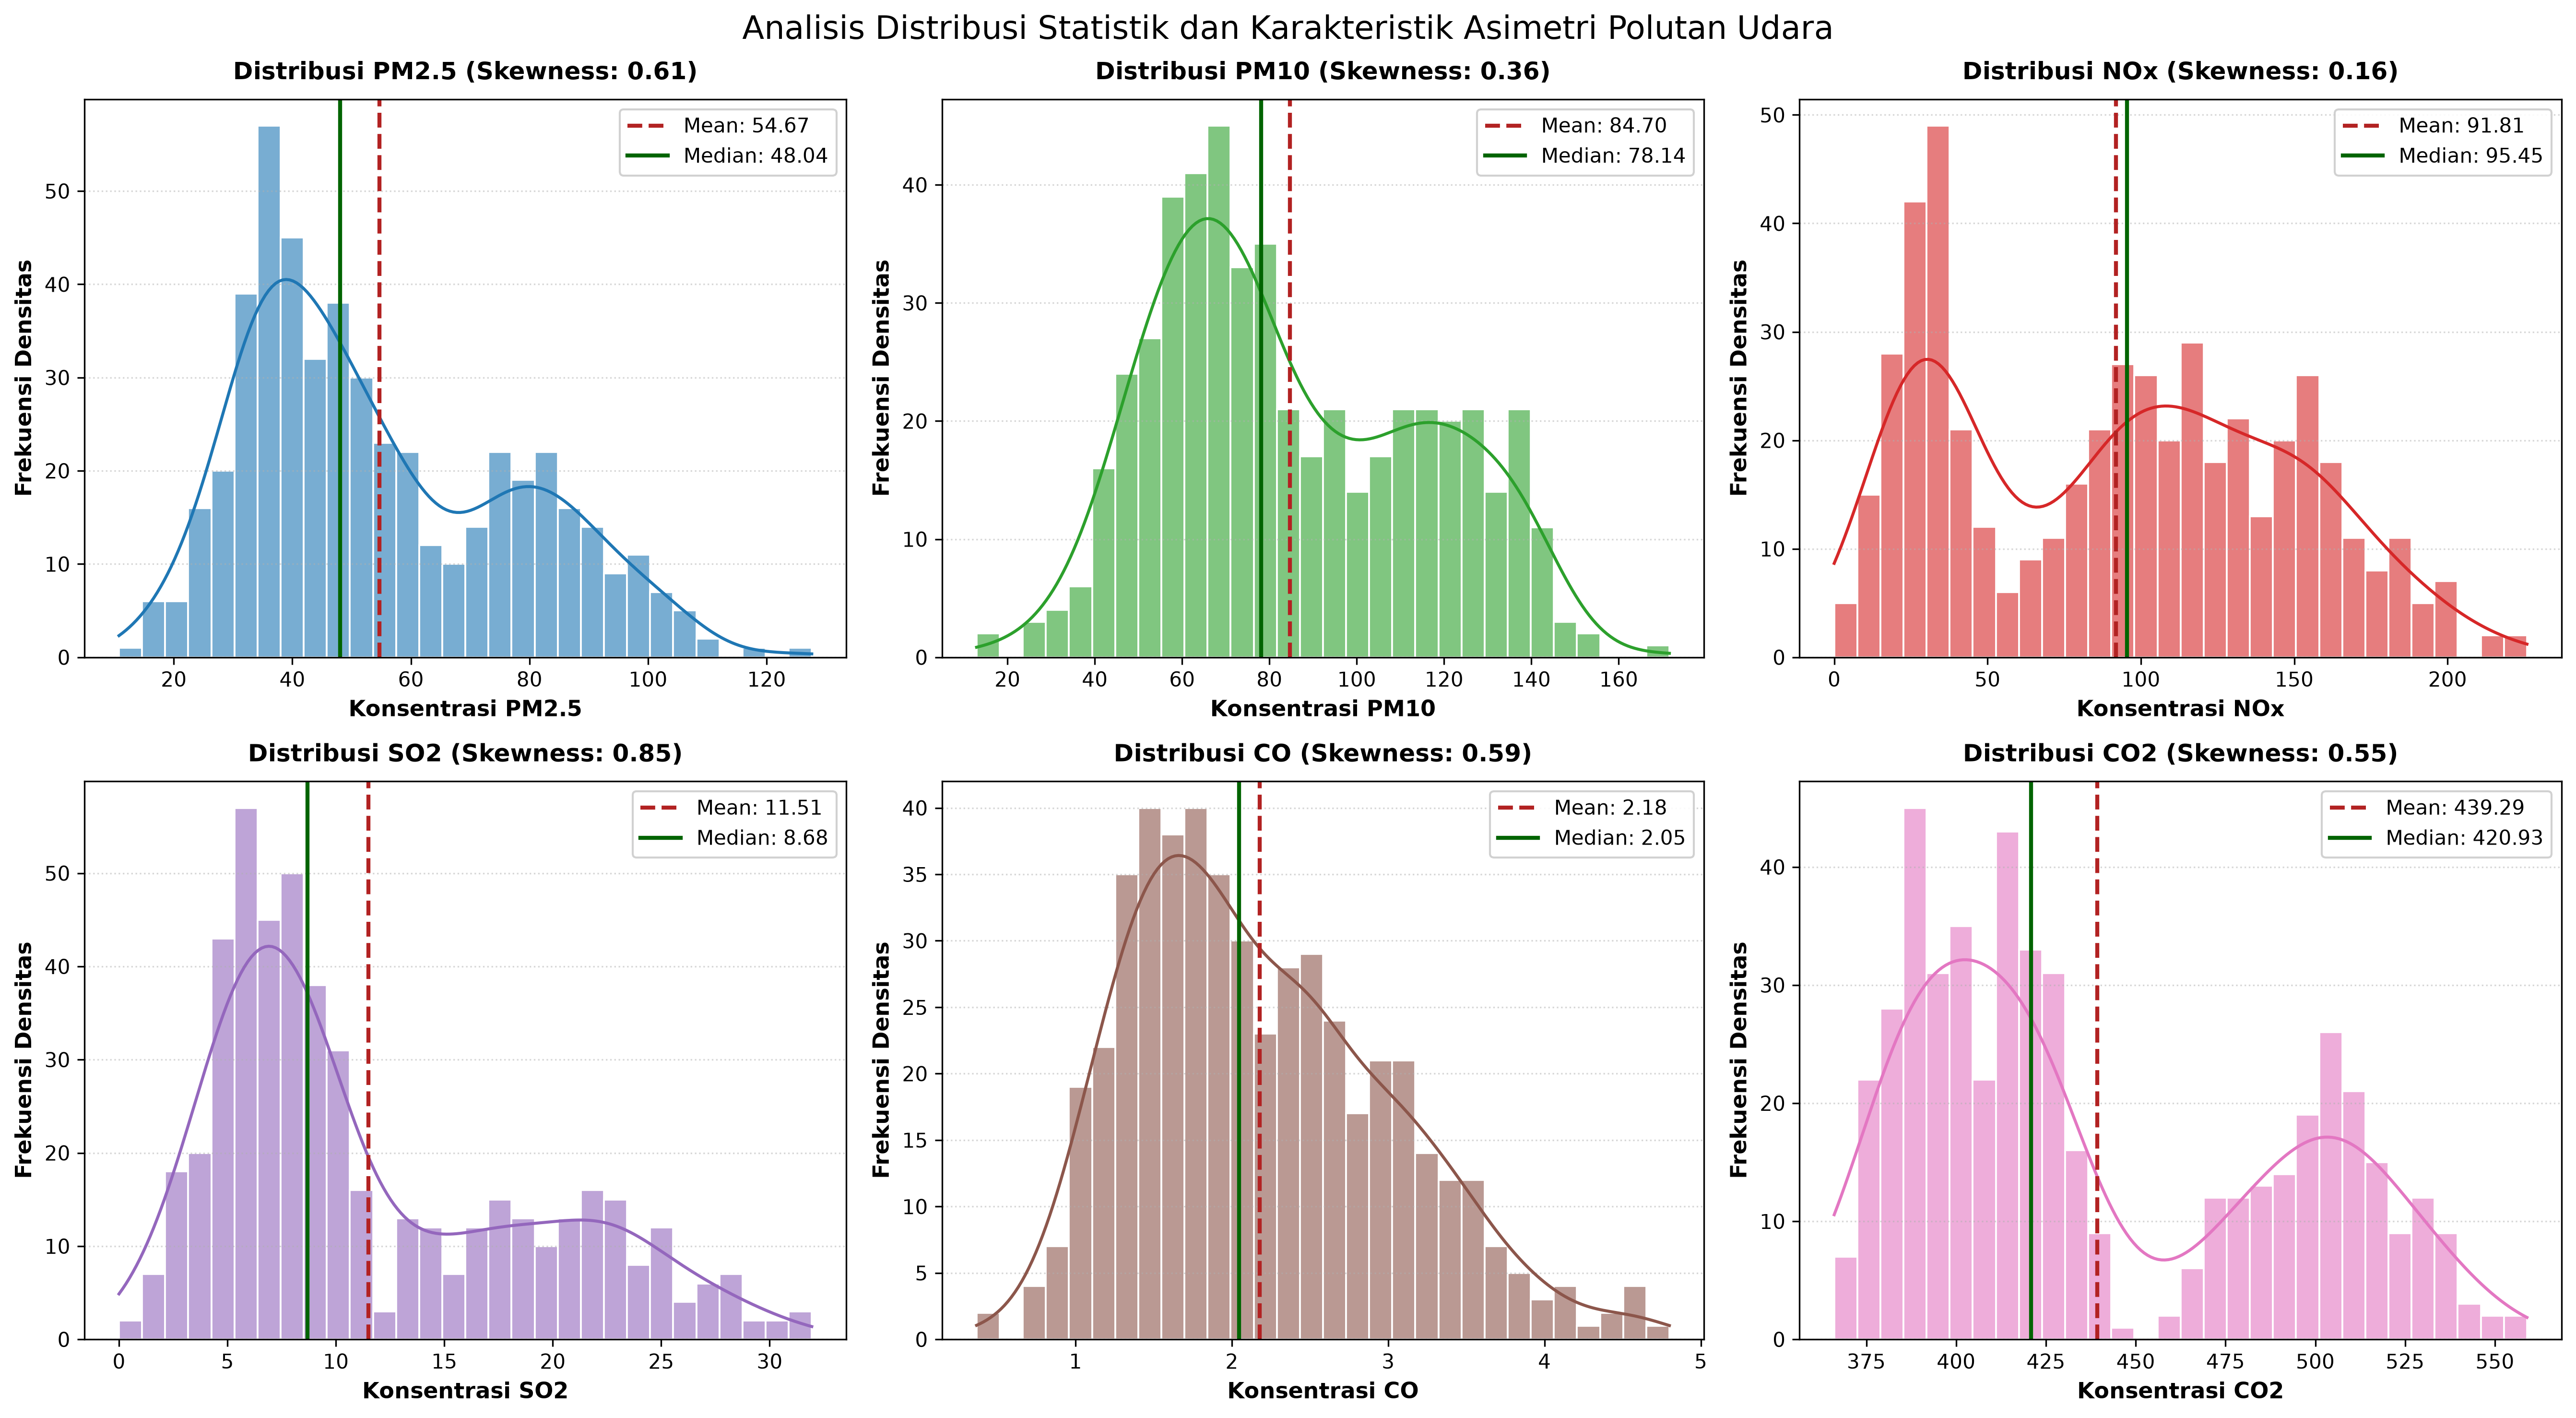

Aset Portofolio Tersimpan: portfolio_assets\01_pollutant_distributions.png


In [5]:
# Sel 5: Visualisasi 1 - Distribusi dan Uji Asimetri Polutan Utama

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

selected_pollutants = ['PM2.5', 'PM10', 'NOx', 'SO2', 'CO', 'CO2']
palette_colors = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

for idx, (param, color) in enumerate(zip(selected_pollutants, palette_colors)):
    ax = axes[idx]
    sns.histplot(df[param], kde=True, ax=ax, color=color, bins=30, alpha=0.6, edgecolor='white')
    
    mean_val = df[param].mean()
    median_val = df[param].median()
    skew_val = df[param].skew()
    
    ax.axvline(mean_val, color='#b22222', linestyle='--', linewidth=2, label=f"Mean: {mean_val:.2f}")
    ax.axvline(median_val, color='#006400', linestyle='-', linewidth=2, label=f"Median: {median_val:.2f}")
    
    ax.set_title(f"Distribusi {param} (Skewness: {skew_val:.2f})", fontsize=12, pad=10)
    ax.set_xlabel(f"Konsentrasi {param}")
    ax.set_ylabel("Frekuensi Densitas")
    ax.legend(frameon=True, facecolor='white', framealpha=0.9)
    ax.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Analisis Distribusi Statistik dan Karakteristik Asimetri Polutan Udara", fontsize=16, y=0.98)
plt.tight_layout()

# Penyimpanan Grafik untuk Aset Portofolio
fig1_path = OUTPUT_DIR / '01_pollutant_distributions.png'
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig1_path}")


### Visualisasi 2: Matriks Korelasi Multivariat (Pearson Linear & Spearman Monotonik)

Korelasi linear Pearson mengukur kekuatan hubungan linear antar-variabel, sedangkan korelasi rank Spearman mengukur hubungan monotonik (baik linear maupun non-linear). Perbandingan kedua matriks ini mengungkap dinamika interaksi polutan di atmosfer:
- **Korelasi Tinggi Antara CO2, NOx, dan NO2**: Menunjukkan emisi primer yang berasal dari sumber pembakaran intensif bahan bakar fosil.
- **Korelasi Kuat SO2 dan PM10**: Mengindikasikan pembentukan partikulat sekunder akibat reaksi fotokimia sulfur oksida.


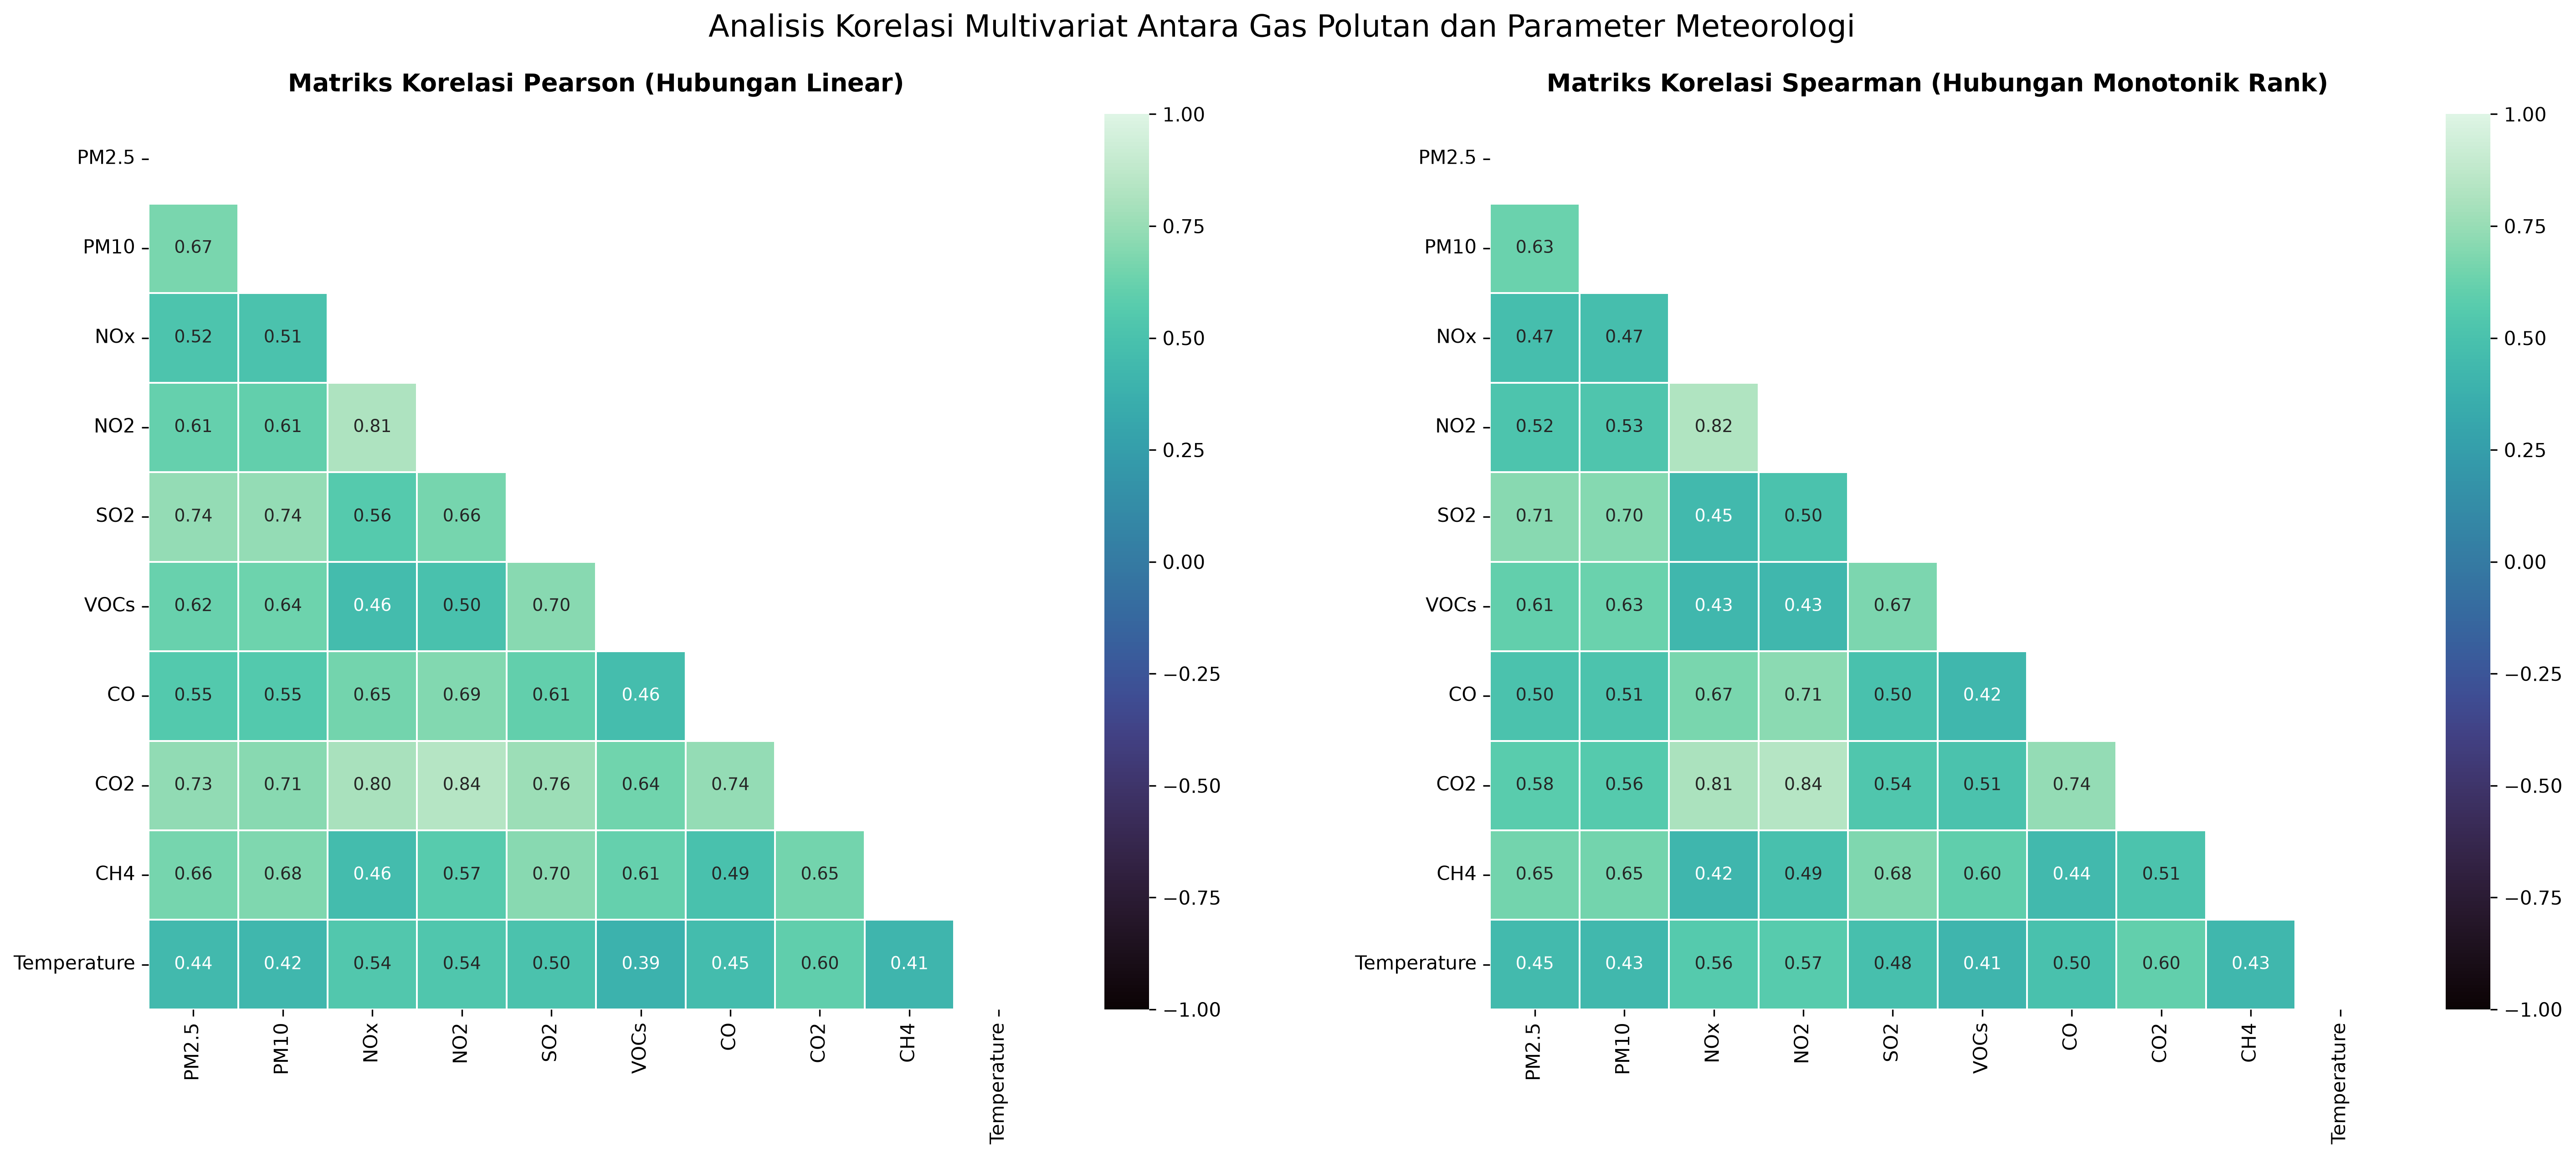

Aset Portofolio Tersimpan: portfolio_assets\02_multivariate_correlation_matrix.png


In [6]:
# Sel 6: Visualisasi 2 - Perbandingan Matriks Korelasi Pearson dan Spearman

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Matriks Pearson
corr_pearson = df.corr(method='pearson')
mask_p = np.triu(np.ones_like(corr_pearson, dtype=bool))
sns.heatmap(
    corr_pearson, mask=mask_p, annot=True, fmt='.2f', cmap='mako',
    cbar=True, ax=axes[0], vmin=-1.0, vmax=1.0, linewidths=0.5,
    square=True, annot_kws={'size': 9}
)
axes[0].set_title("Matriks Korelasi Pearson (Hubungan Linear)", fontsize=13, pad=12)

# Matriks Spearman
corr_spearman = df.corr(method='spearman')
mask_s = np.triu(np.ones_like(corr_spearman, dtype=bool))
sns.heatmap(
    corr_spearman, mask=mask_s, annot=True, fmt='.2f', cmap='mako',
    cbar=True, ax=axes[1], vmin=-1.0, vmax=1.0, linewidths=0.5,
    square=True, annot_kws={'size': 9}
)
axes[1].set_title("Matriks Korelasi Spearman (Hubungan Monotonik Rank)", fontsize=13, pad=12)

plt.suptitle("Analisis Korelasi Multivariat Antara Gas Polutan dan Parameter Meteorologi", fontsize=16, y=1.02)
plt.tight_layout()

fig2_path = OUTPUT_DIR / '02_multivariate_correlation_matrix.png'
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig2_path}")


### Visualisasi 3: Pengaruh Dinamika Suhu terhadap Dispersi dan Konsentrasi Gas Polutan

Suhu lingkungan (*Temperature*) mempengaruhi laju difusi atmosfer, ketinggian lapisan batas pencampuran (*boundary layer height*), serta laju reaksi fotokimia pembentukan polutan sekunder. Scatter plot di bawah ini memetakan bagaimana kenaikan suhu berkorelasi dengan eskalasi konsentrasi gas pembakaran utama.


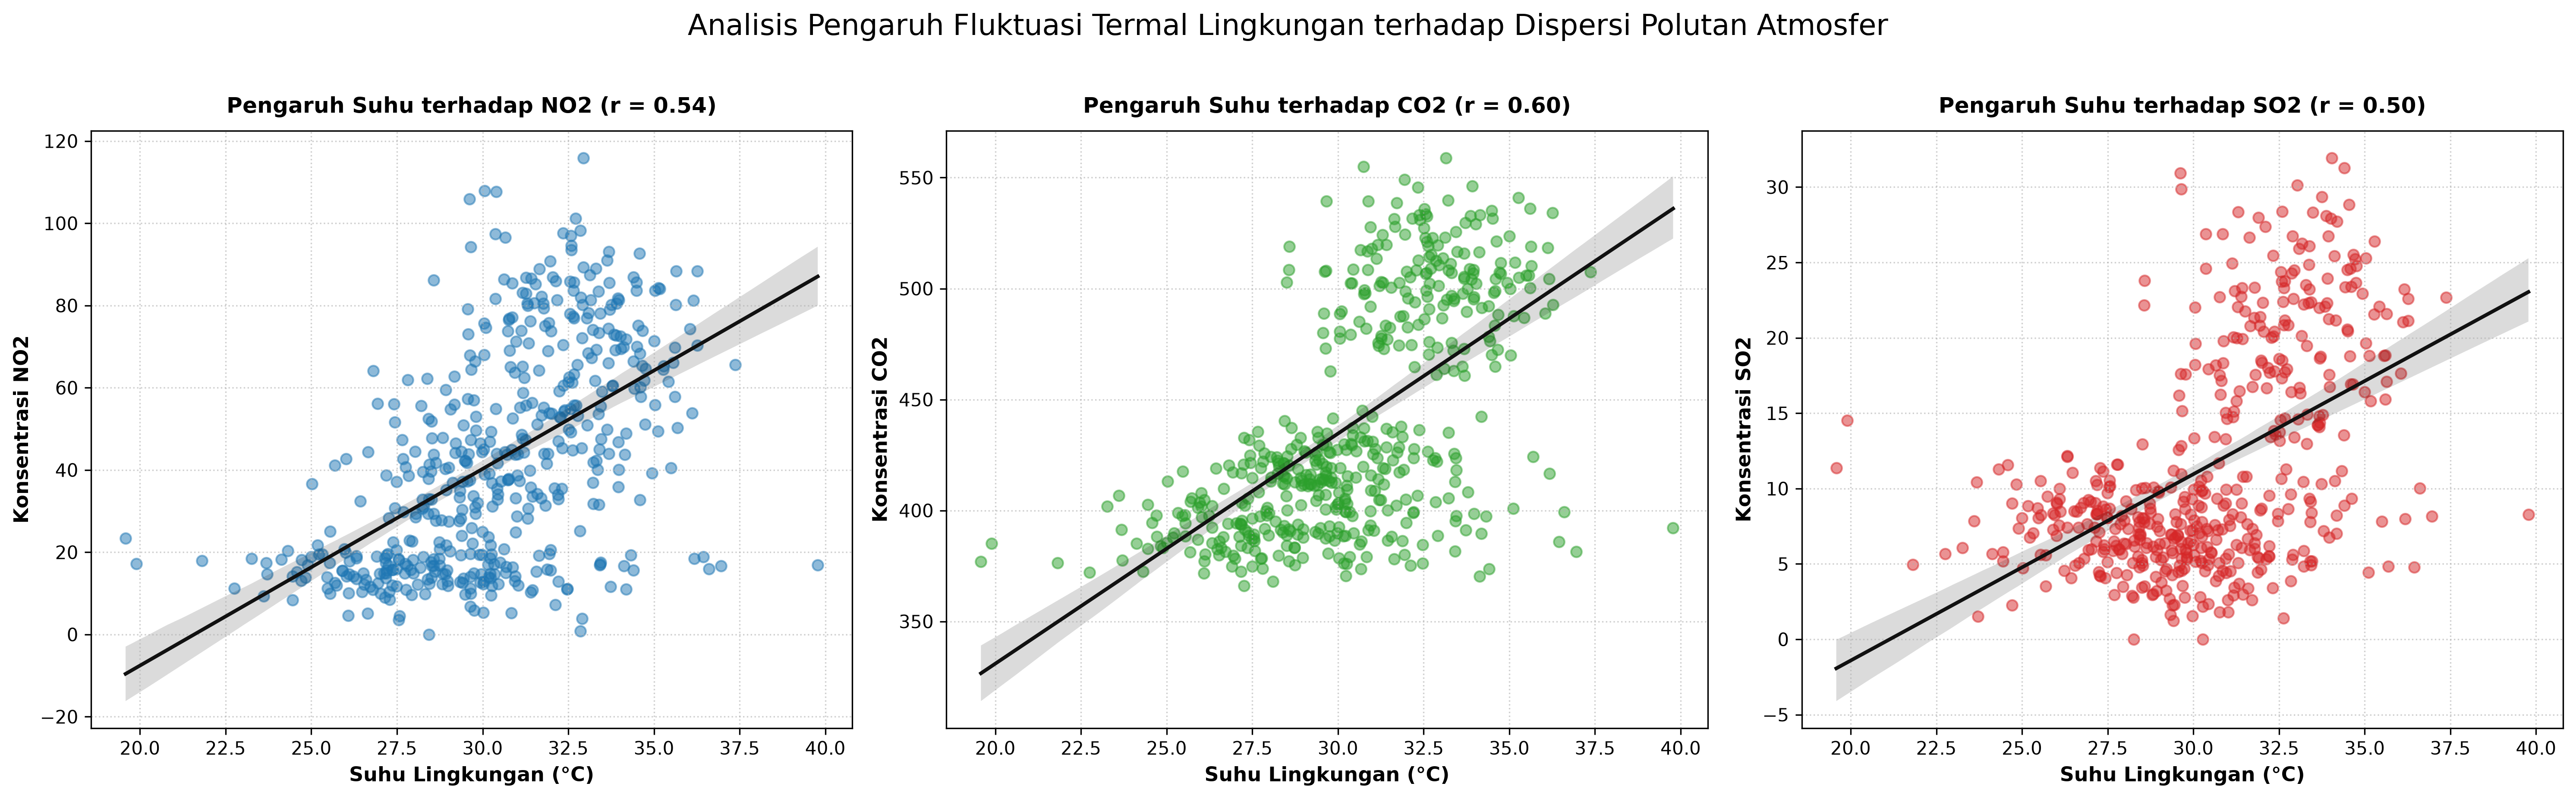

Aset Portofolio Tersimpan: portfolio_assets\03_temperature_impact_analysis.png


In [7]:
# Sel 7: Visualisasi 3 - Hubungan Suhu terhadap Konsentrasi Gas Polutan

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

pollutants_vs_temp = [('NO2', '#1f77b4'), ('CO2', '#2ca02c'), ('SO2', '#d62728')]

for idx, (param, color) in enumerate(pollutants_vs_temp):
    ax = axes[idx]
    sns.regplot(
        data=df, x='Temperature', y=param, ax=ax,
        scatter_kws={'alpha': 0.5, 'color': color, 's': 35},
        line_kws={'color': '#111111', 'linewidth': 2, 'linestyle': '-'}
    )
    r_val = df['Temperature'].corr(df[param])
    ax.set_title(f"Pengaruh Suhu terhadap {param} (r = {r_val:.2f})", fontsize=12, pad=10)
    ax.set_xlabel("Suhu Lingkungan (°C)")
    ax.set_ylabel(f"Konsentrasi {param}")
    ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Analisis Pengaruh Fluktuasi Termal Lingkungan terhadap Dispersi Polutan Atmosfer", fontsize=16, y=1.02)
plt.tight_layout()

fig3_path = OUTPUT_DIR / '03_temperature_impact_analysis.png'
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig3_path}")


### Visualisasi 4: Analisis Rasio Particulate Matter ($PM_{2.5} / PM_{10}$)

Rasio $PM_{2.5} / PM_{10}$ merupakan indikator penting dalam pemodelan kualitas udara:
- **Rasio Tinggi (> 0.6)**: Menunjukkan dominasi partikel halus antropogenik yang berasal dari pembakaran bahan bakar kendaraan bermotor atau aktivitas industri bertekanan tinggi.
- **Rasio Rendah (< 0.5)**: Menunjukkan dominasi partikel kasar mekanis, seperti debu jalanan, debu padang pasir, atau aktivitas konstruksi fisik.


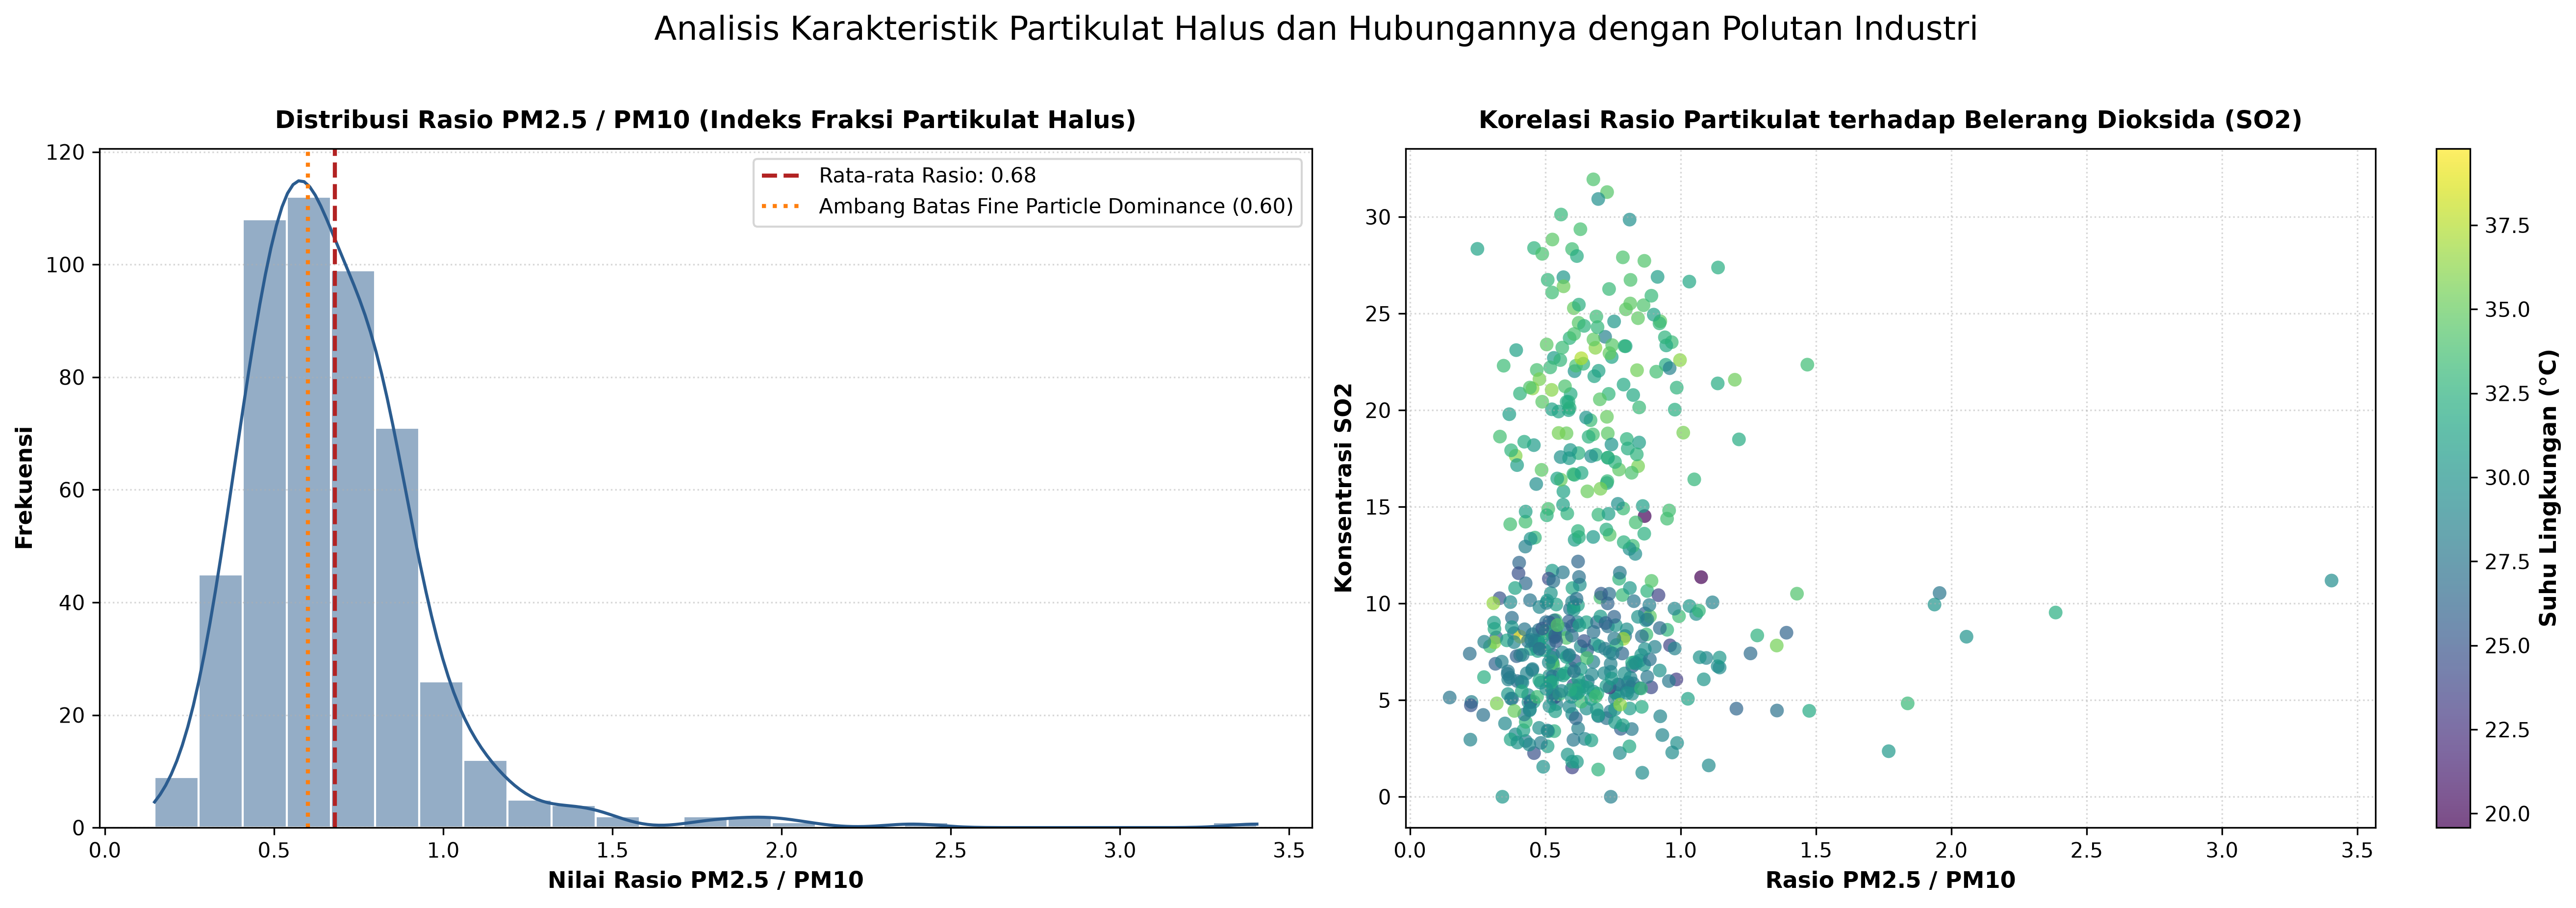

Aset Portofolio Tersimpan: portfolio_assets\04_pm_ratio_analysis.png


In [8]:
# Sel 8: Visualisasi 4 - Analisis Rasio Partikulat PM2.5 / PM10

df_ratio = df.copy()
df_ratio['PM_Ratio'] = df_ratio['PM2.5'] / df_ratio['PM10'].replace(0, np.nan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Histogram Rasio Partikulat
sns.histplot(df_ratio['PM_Ratio'], kde=True, ax=ax1, color='#2b5c8f', bins=25, edgecolor='white')
mean_ratio = df_ratio['PM_Ratio'].mean()
ax1.axvline(mean_ratio, color='#b22222', linestyle='--', linewidth=2, label=f"Rata-rata Rasio: {mean_ratio:.2f}")
ax1.axvline(0.6, color='#ff7f0e', linestyle=':', linewidth=2, label="Ambang Batas Fine Particle Dominance (0.60)")
ax1.set_title("Distribusi Rasio PM2.5 / PM10 (Indeks Fraksi Partikulat Halus)", fontsize=12, pad=10)
ax1.set_xlabel("Nilai Rasio PM2.5 / PM10")
ax1.set_ylabel("Frekuensi")
ax1.legend(frameon=True, facecolor='white')
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# Scatter Rasio terhadap Konsentrasi SO2 dengan Hue Suhu
scatter = ax2.scatter(
    df_ratio['PM_Ratio'], df_ratio['SO2'],
    c=df_ratio['Temperature'], cmap='viridis', alpha=0.7, edgecolors='none', s=45
)
cbar = fig.colorbar(scatter, ax=ax2)
cbar.set_label("Suhu Lingkungan (°C)")
ax2.set_title("Korelasi Rasio Partikulat terhadap Belerang Dioksida (SO2)", fontsize=12, pad=10)
ax2.set_xlabel("Rasio PM2.5 / PM10")
ax2.set_ylabel("Konsentrasi SO2")
ax2.grid(True, linestyle=':', alpha=0.5)

plt.suptitle("Analisis Karakteristik Partikulat Halus dan Hubungannya dengan Polutan Industri", fontsize=16, y=1.02)
plt.tight_layout()

fig4_path = OUTPUT_DIR / '04_pm_ratio_analysis.png'
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig4_path}")


---
## Modul 4: Rekayasa Fitur Kimia Atmosfer & Formulasi Target Multi-Objektif

### Formulasi Fitur Domain Kimia Atmosfer
Berdasarkan prinsip kimia atmosfer terapan, kita merekayasa fitur-fitur interaktif berikut:
1. **`PM_Ratio` ($PM_{2.5} / PM_{10}$)**: Menangkap fraksi aerosol respirabel yang dapat masuk ke alveolus paru-paru.
2. **`Oxidation_Ratio` ($NO_2 / NOx$)**: Rasio efisiensi fotooksidasi nitrogen monoksida menjadi nitrogen dioksida akibat keberadaan ozon dan radiasi ultraviolet.
3. **`Combustion_Efficiency_Index` ($CO / CO_2$)**: Rasio ketidaksempurnaan pembakaran motorik/industri (semakin tinggi, semakin buruk efisiensi pembakaran mesin).
4. **`Thermal_VOC_Interaction` ($Temperature \times VOCs$)**: Interaksi termal terhadap penguapan senyawa organik volatil.

### Formulasi Target Klasifikasi: Kategori Risiko Kualitas Udara
Berdasarkan standar baku mutu konsentrasi partikulat halus harian dari badan kesehatan dunia (WHO) dan US EPA:
- **`Baik (Good)`**: Konsentrasi $PM_{2.5} \le 35.0\ \mu\text{g/m}^3$ (Kualitas udara optimal, risiko minimal bagi populasi rentan).
- **`Sedang (Moderate)`**: Konsentrasi $35.0 < PM_{2.5} \le 75.0\ \mu\text{g/m}^3$ (Kualitas udara dapat diterima, namun polutan tertentu dapat mempengaruhi individu sensitif).
- **`Tidak Sehat (Unhealthy)`**: Konsentrasi $PM_{2.5} > 75.0\ \mu\text{g/m}^3$ (Risiko kesehatan meluas bagi seluruh populasi perkotaan).


In [9]:
# Sel 9: Komputasi Rekayasa Fitur dan Formulasi Target Klasifikasi

df_engineered = df.copy()

# 1. Rekayasa Fitur Domain
df_engineered['PM_Ratio'] = df_engineered['PM2.5'] / df_engineered['PM10'].replace(0, np.nan)
df_engineered['Oxidation_Ratio'] = df_engineered['NO2'] / df_engineered['NOx'].replace(0, np.nan)
df_engineered['Combustion_Index'] = df_engineered['CO'] / df_engineered['CO2'].replace(0, np.nan)
df_engineered['Thermal_VOC_Interaction'] = df_engineered['Temperature'] * df_engineered['VOCs']

# Tangani potensi pembagian dengan nilai nol / NaN
df_engineered.fillna(df_engineered.median(numeric_only=True), inplace=True)

# 2. Formulasi Kategori Kualitas Udara (Target Klasifikasi Multi-Kelas)
def categorize_air_quality(pm25_val: float) -> str:
    if pm25_val <= 35.0:
        return 'Baik'
    elif pm25_val <= 75.0:
        return 'Sedang'
    else:
        return 'Tidak Sehat'

df_engineered['Air_Quality_Category'] = df_engineered['PM2.5'].apply(categorize_air_quality)

# Distribusi Kelas Kategori
class_distribution = df_engineered['Air_Quality_Category'].value_counts()
print("=== Distribusi Sampel Kategori Kualitas Udara ===")
for cat, count in class_distribution.items():
    pct = (count / len(df_engineered)) * 100
    print(f"Kategori '{cat}': {count} observasi ({pct:.2f}%)")

df_engineered[['PM2.5', 'PM_Ratio', 'Oxidation_Ratio', 'Combustion_Index', 'Thermal_VOC_Interaction', 'Air_Quality_Category']].head()


=== Distribusi Sampel Kategori Kualitas Udara ===
Kategori 'Sedang': 285 observasi (57.00%)
Kategori 'Tidak Sehat': 115 observasi (23.00%)
Kategori 'Baik': 100 observasi (20.00%)


,PM2.5,PM_Ratio,Oxidation_Ratio,Combustion_Index,Thermal_VOC_Interaction,Air_Quality_Category
0,39.967142,0.689969,0.475336,0.006523,2341.246099,Sedang
1,101.935672,0.676081,1.028959,0.003712,4890.941159,Tidak Sehat
2,70.996192,0.510952,0.380938,0.005254,4902.888085,Sedang
3,28.464728,0.447250,0.604021,0.004583,4104.268562,Baik
4,78.265276,0.686670,0.560393,0.006973,5856.601578,Tidak Sehat


### Visualisasi 5: Pemetaan Karakteristik Polutan Gas pada Setiap Kategori Kualitas Udara

Visualisasi boxplot terstandardisasi di bawah ini memperlihatkan bagaimana sebaran gas pembakaran ($NO_2, SO_2, CO$) meningkat secara konsisten seiring dengan memburuknya kategori kualitas udara dari *Baik* ke *Tidak Sehat*.


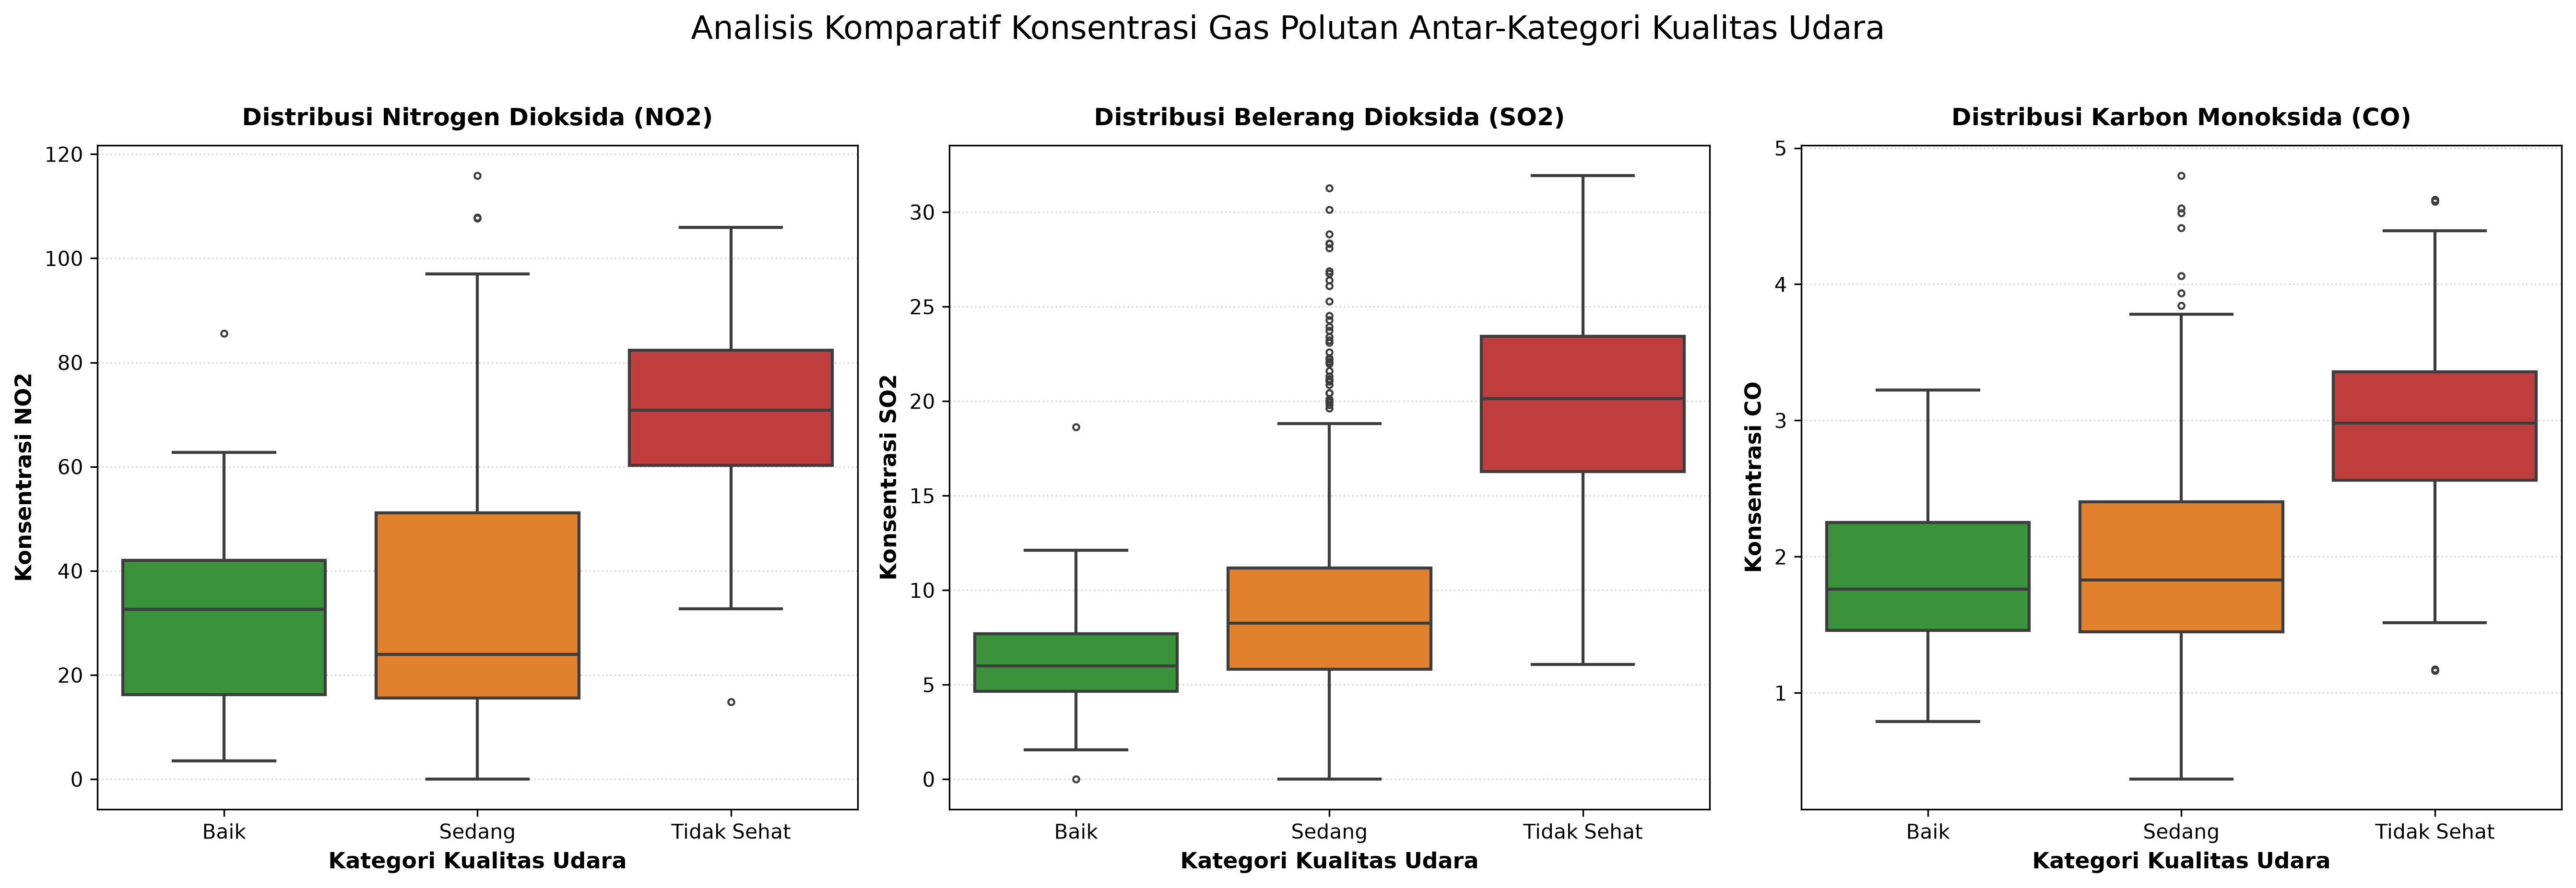

Aset Portofolio Tersimpan: portfolio_assets\05_category_pollutant_characteristics.png


In [10]:
# Sel 10: Visualisasi 5 - Karakteristik Polutan Gas Berdasarkan Kategori Kualitas Udara

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

features_to_plot = [('NO2', 'Nitrogen Dioksida (NO2)'), ('SO2', 'Belerang Dioksida (SO2)'), ('CO', 'Karbon Monoksida (CO)')]
category_order = ['Baik', 'Sedang', 'Tidak Sehat']
palette_cat = {'Baik': '#2ca02c', 'Sedang': '#ff7f0e', 'Tidak Sehat': '#d62728'}

for idx, (param, label) in enumerate(features_to_plot):
    ax = axes[idx]
    sns.boxplot(
        data=df_engineered, x='Air_Quality_Category', y=param,
        order=category_order, palette=palette_cat, ax=ax,
        fliersize=3, linewidth=1.5
    )
    ax.set_title(f"Distribusi {label}", fontsize=12, pad=10)
    ax.set_xlabel("Kategori Kualitas Udara")
    ax.set_ylabel(f"Konsentrasi {param}")
    ax.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Analisis Komparatif Konsentrasi Gas Polutan Antar-Kategori Kualitas Udara", fontsize=16, y=1.02)
plt.tight_layout()

fig5_path = OUTPUT_DIR / '05_category_pollutant_characteristics.png'
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig5_path}")


---
## Modul 5: Tugas 1 - Pemodelan Regresi Estimasi Konsentrasi Polutan Partikulat ($PM_{2.5}$)

### Desain Eksperimen dan Formulasi Masalah Regresi
- **Target Variabel ($y$)**: Konsentrasi partikulat halus $PM_{2.5}$.
- **Fitur Prediktor ($X$)**: Seluruh parameter gas, sensor meteorologi, dan fitur rekayasa kimia atmosfer:
  `['PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature', 'Oxidation_Ratio', 'Combustion_Index', 'Thermal_VOC_Interaction']`.
- **Skema Validasi**: 5-Fold Cross Validation dengan pemisahan Hold-out Test Set (80% Pelatihan, 20% Pengujian).
- **Metrik Evaluasi**:
  1. **RMSE (Root Mean Squared Error)**: Mengukur deviasi kuadrat rata-rata dengan penalti tinggi pada kesalahan ekstrem.
  2. **MAE (Mean Absolute Error)**: Mengukur deviasi absolut rata-rata yang lebih tahan terhadap outlier.
  3. **R-Squared ($R^2$)**: Proporsi varians target yang mampu dijelaskan oleh model fitur.

### Algoritma yang Dibandingkan (Model Benchmarking)
1. **Ridge Regression (Baseline Linear)**: Menggunakan regularisasi L2 penalty untuk membatasi multikolinearitas antar-sensor.
2. **Random Forest Regressor (Ensemble Bagging)**: Membangun agregasi pohon keputusan independen untuk menangkap interaksi non-linear.
3. **XGBoost Regressor (Gradient Boosting)**: Mengoptimalkan fungsi loss secara iteratif dengan penalti kompleksitas pohon.


In [11]:
# Sel 11: Implementasi Pipeline Regresi dan Benchmarking Multi-Model

# Penyiapan Matriks Fitur dan Vektor Target Regresi
feature_cols_reg = [
    'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4',
    'Temperature', 'Oxidation_Ratio', 'Combustion_Index', 'Thermal_VOC_Interaction'
]
X_reg = df_engineered[feature_cols_reg]
y_reg = df_engineered['PM2.5']

# Pembagian Dataset 80:20 Terkontrol
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# Standardisasi Skala Fitur Menggunakan StandardScaler
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Definisi Model Regresi
models_reg = {
    'Ridge Regression (Baseline)': Ridge(alpha=1.0, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1),
    'XGBoost Regressor': xgb.XGBRegressor(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42, n_jobs=-1)
}

# Evaluasi 5-Fold Cross Validation dan Evaluasi Test Set
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results_reg = []
fitted_reg_models = {}
predictions_reg = {}

for name, model in models_reg.items():
    # 5-Fold Cross Validation pada Data Latih (Skala Terstandardisasi)
    cv_r2 = cross_val_score(model, X_train_reg_scaled, y_train_reg, cv=kf, scoring='r2').mean()
    cv_rmse = np.sqrt(-cross_val_score(model, X_train_reg_scaled, y_train_reg, cv=kf, scoring='neg_mean_squared_error')).mean()
    
    # Pelatihan Model pada Seluruh Data Latih
    model.fit(X_train_reg_scaled, y_train_reg)
    fitted_reg_models[name] = model
    
    # Inferensi pada Data Uji Independen
    y_pred = model.predict(X_test_reg_scaled)
    predictions_reg[name] = y_pred
    
    test_rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred))
    test_mae = mean_absolute_error(y_test_reg, y_pred)
    test_r2 = r2_score(y_test_reg, y_pred)
    
    results_reg.append({
        'Model': name,
        'CV R2': cv_r2,
        'CV RMSE': cv_rmse,
        'Test RMSE': test_rmse,
        'Test MAE': test_mae,
        'Test R2': test_r2
    })

df_results_reg = pd.DataFrame(results_reg)
print("=== Tabel Hasil Benchmarking Model Regresi PM2.5 ===")
df_results_reg.round(4)


=== Tabel Hasil Benchmarking Model Regresi PM2.5 ===


,Model,CV R2,CV RMSE,Test RMSE,Test MAE,Test R2
0,Ridge Regression (Baseline),0.6131,13.7616,14.6112,11.0408,0.6231
1,Random Forest Regressor,0.6312,13.4416,13.8341,10.6760,0.6621
2,XGBoost Regressor,0.6124,13.8186,13.7341,10.8046,0.6670


### Visualisasi 6: Evaluasi Performa Regresi dan Analisis Residual Model Terbaik

Analisis residual ($e_i = y_i - \hat{y}_i$) memverifikasi asumsi error model: residual harus terdistribusi secara simetris di sekitar nol tanpa adanya pola heterokedastisitas sistematis.


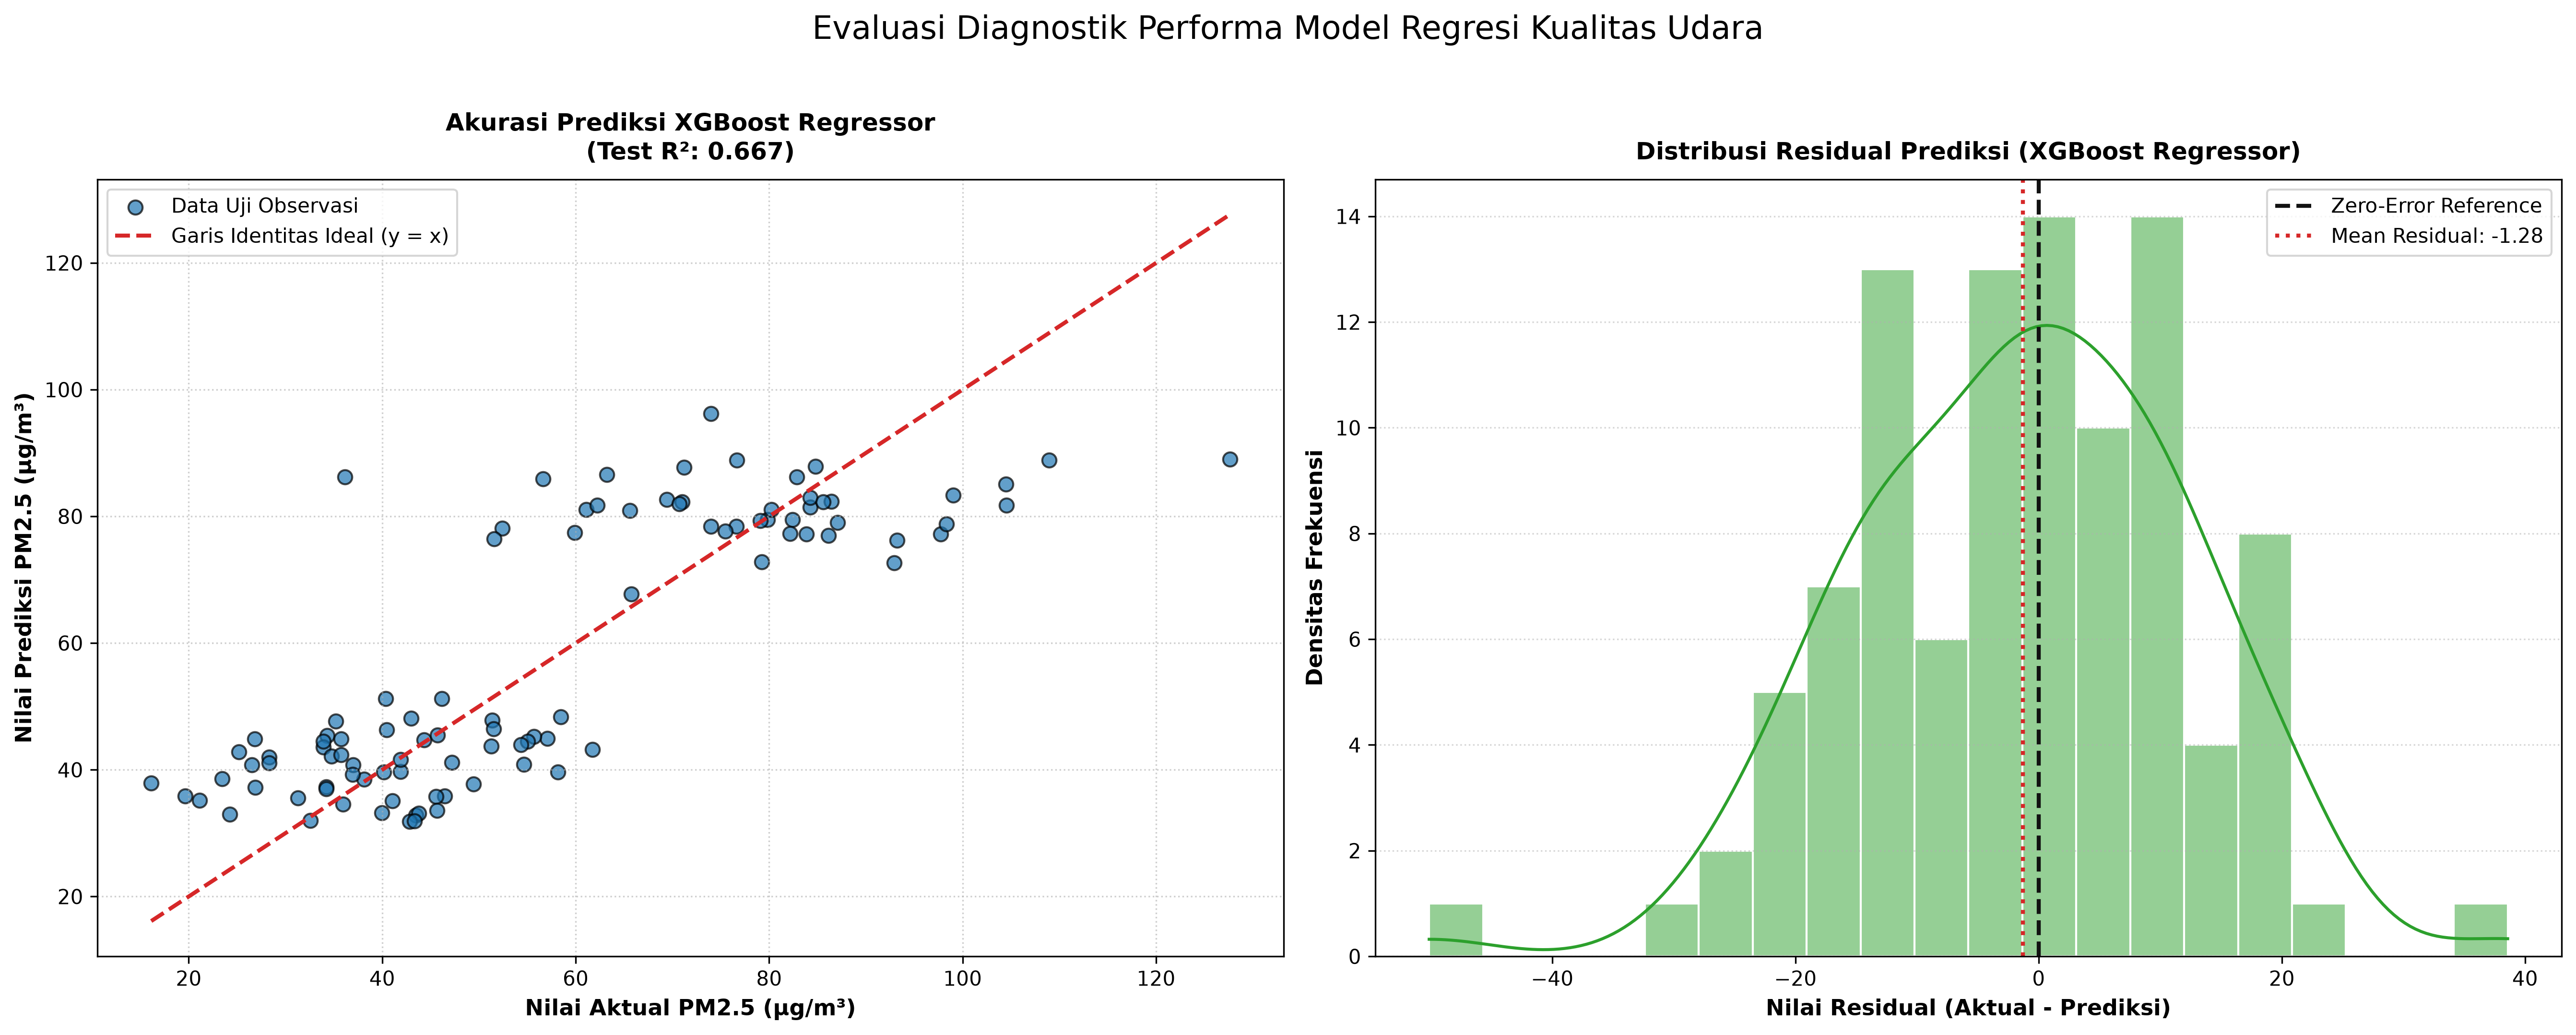

Aset Portofolio Tersimpan: portfolio_assets\06_regression_performance_diagnostics.png


In [12]:
# Sel 12: Visualisasi 6 - Evaluasi Aktual vs Prediksi dan Analisis Residual Regresi

# Tentukan model terbaik berdasarkan Test R2
best_reg_name = df_results_reg.sort_values(by='Test R2', ascending=False).iloc[0]['Model']
best_y_pred = predictions_reg[best_reg_name]
residuals = y_test_reg - best_y_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# 1. Scatter Plot Aktual vs Prediksi
ax1.scatter(y_test_reg, best_y_pred, alpha=0.7, color='#1f77b4', edgecolors='k', s=50, label='Data Uji Observasi')
min_val = min(y_test_reg.min(), best_y_pred.min())
max_val = max(y_test_reg.max(), best_y_pred.max())
ax1.plot([min_val, max_val], [min_val, max_val], color='#d62728', linestyle='--', linewidth=2, label='Garis Identitas Ideal (y = x)')

ax1.set_title(f"Akurasi Prediksi {best_reg_name}\n(Test R²: {r2_score(y_test_reg, best_y_pred):.3f})", fontsize=12, pad=10)
ax1.set_xlabel("Nilai Aktual PM2.5 (µg/m³)")
ax1.set_ylabel("Nilai Prediksi PM2.5 (µg/m³)")
ax1.legend(frameon=True, facecolor='white')
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Distribusi Residual
sns.histplot(residuals, kde=True, ax=ax2, color='#2ca02c', bins=20, edgecolor='white')
ax2.axvline(0, color='#111111', linestyle='--', linewidth=2, label="Zero-Error Reference")
ax2.axvline(residuals.mean(), color='#d62728', linestyle=':', linewidth=2, label=f"Mean Residual: {residuals.mean():.2f}")
ax2.set_title(f"Distribusi Residual Prediksi ({best_reg_name})", fontsize=12, pad=10)
ax2.set_xlabel("Nilai Residual (Aktual - Prediksi)")
ax2.set_ylabel("Densitas Frekuensi")
ax2.legend(frameon=True, facecolor='white')
ax2.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Evaluasi Diagnostik Performa Model Regresi Kualitas Udara", fontsize=16, y=1.02)
plt.tight_layout()

fig6_path = OUTPUT_DIR / '06_regression_performance_diagnostics.png'
plt.savefig(fig6_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig6_path}")


---
## Modul 6: Tugas 2 - Pemodelan Klasifikasi Multi-Kelas Kategori Risiko Kualitas Udara

### Desain Eksperimen dan Formulasi Masalah Klasifikasi
- **Target Variabel ($y$)**: `Air_Quality_Category` (*Baik*, *Sedang*, *Tidak Sehat*).
- **Pencegahan Data Leakage (Anti-Leakage Strategy)**:
  Fitur $PM_{2.5}$ dan $PM_{10}$ dikeluarkan dari matriks prediktor $X$ karena kategori kualitas udara diturunkan langsung dari $PM_{2.5}$. Model dituntut untuk memprediksi tingkat bahaya polusi secara tidak langsung hanya dari sensor gas pembakaran dan parameter lingkungan:
  `['NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature', 'Oxidation_Ratio', 'Combustion_Index', 'Thermal_VOC_Interaction']`.
- **Skema Validasi**: Stratified 5-Fold Cross Validation untuk menjaga proporsi label kelas yang seimbang di setiap fold.
- **Metrik Evaluasi**: Macro-averaged F1-Score, Macro Precision, Macro Recall, dan Overall Accuracy.
- **Algoritma yang Dibandingkan**:
  1. **Multinomial Logistic Regression (Baseline)**.
  2. **Random Forest Classifier (Ensemble Bagging)**.
  3. **XGBoost Classifier (Multi-class Softmax Gradient Boosting)**.


In [13]:
# Sel 13: Implementasi Pipeline Klasifikasi Multi-Kelas dan Benchmarking

# Penyiapan Matriks Fitur (Bebas Leakage) dan Vektor Target Klasifikasi
feature_cols_clf = [
    'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4',
    'Temperature', 'Oxidation_Ratio', 'Combustion_Index', 'Thermal_VOC_Interaction'
]
X_clf = df_engineered[feature_cols_clf]

label_encoder = LabelEncoder()
y_clf = label_encoder.fit_transform(df_engineered['Air_Quality_Category'])
class_names = list(label_encoder.classes_)

# Pembagian Dataset 80:20 Terstratifikasi
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

# Standardisasi Skala Fitur
scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

# Definisi Model Klasifikasi
models_clf = {
    'Logistic Regression (Baseline)': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42, n_jobs=-1),
    'XGBoost Classifier': xgb.XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, eval_metric='mlogloss', random_state=42, n_jobs=-1)
}

# Evaluasi Stratified 5-Fold CV dan Evaluasi Test Set
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_clf = []
fitted_clf_models = {}
predictions_clf = {}

for name, model in models_clf.items():
    # Stratified 5-Fold CV pada Data Latih
    cv_f1 = cross_val_score(model, X_train_clf_scaled, y_train_clf, cv=skf, scoring='f1_macro').mean()
    cv_acc = cross_val_score(model, X_train_clf_scaled, y_train_clf, cv=skf, scoring='accuracy').mean()
    
    # Pelatihan Model
    model.fit(X_train_clf_scaled, y_train_clf)
    fitted_clf_models[name] = model
    
    # Inferensi pada Data Uji Independen
    y_pred_clf = model.predict(X_test_clf_scaled)
    predictions_clf[name] = y_pred_clf
    
    test_acc = accuracy_score(y_test_clf, y_pred_clf)
    test_prec = precision_score(y_test_clf, y_pred_clf, average='macro')
    test_rec = recall_score(y_test_clf, y_pred_clf, average='macro')
    test_f1 = f1_score(y_test_clf, y_pred_clf, average='macro')
    
    results_clf.append({
        'Model': name,
        'CV Accuracy': cv_acc,
        'CV F1-Macro': cv_f1,
        'Test Accuracy': test_acc,
        'Test Precision (Macro)': test_prec,
        'Test Recall (Macro)': test_rec,
        'Test F1 (Macro)': test_f1
    })

df_results_clf = pd.DataFrame(results_clf)
print("=== Tabel Hasil Benchmarking Model Klasifikasi Kualitas Udara ===")
df_results_clf.round(4)


=== Tabel Hasil Benchmarking Model Klasifikasi Kualitas Udara ===


,Model,CV Accuracy,CV F1-Macro,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro)
0,Logistic Regression (Baseline),0.6200,0.4804,0.59,0.5013,0.5115,0.4637
1,Random Forest Classifier,0.6300,0.4905,0.63,0.5819,0.5694,0.4987
2,XGBoost Classifier,0.5925,0.5109,0.63,0.6198,0.6128,0.6048


### Visualisasi 7: Confusion Matrix Terstandarisasi dan Evaluasi Laporan Klasifikasi

Confusion Matrix dinormalisasi terhadap jumlah sampel sebenarnya di setiap kelas untuk memberikan gambaran akurat mengenai sensitivitas deteksi kelas mayoritas maupun minoritas.


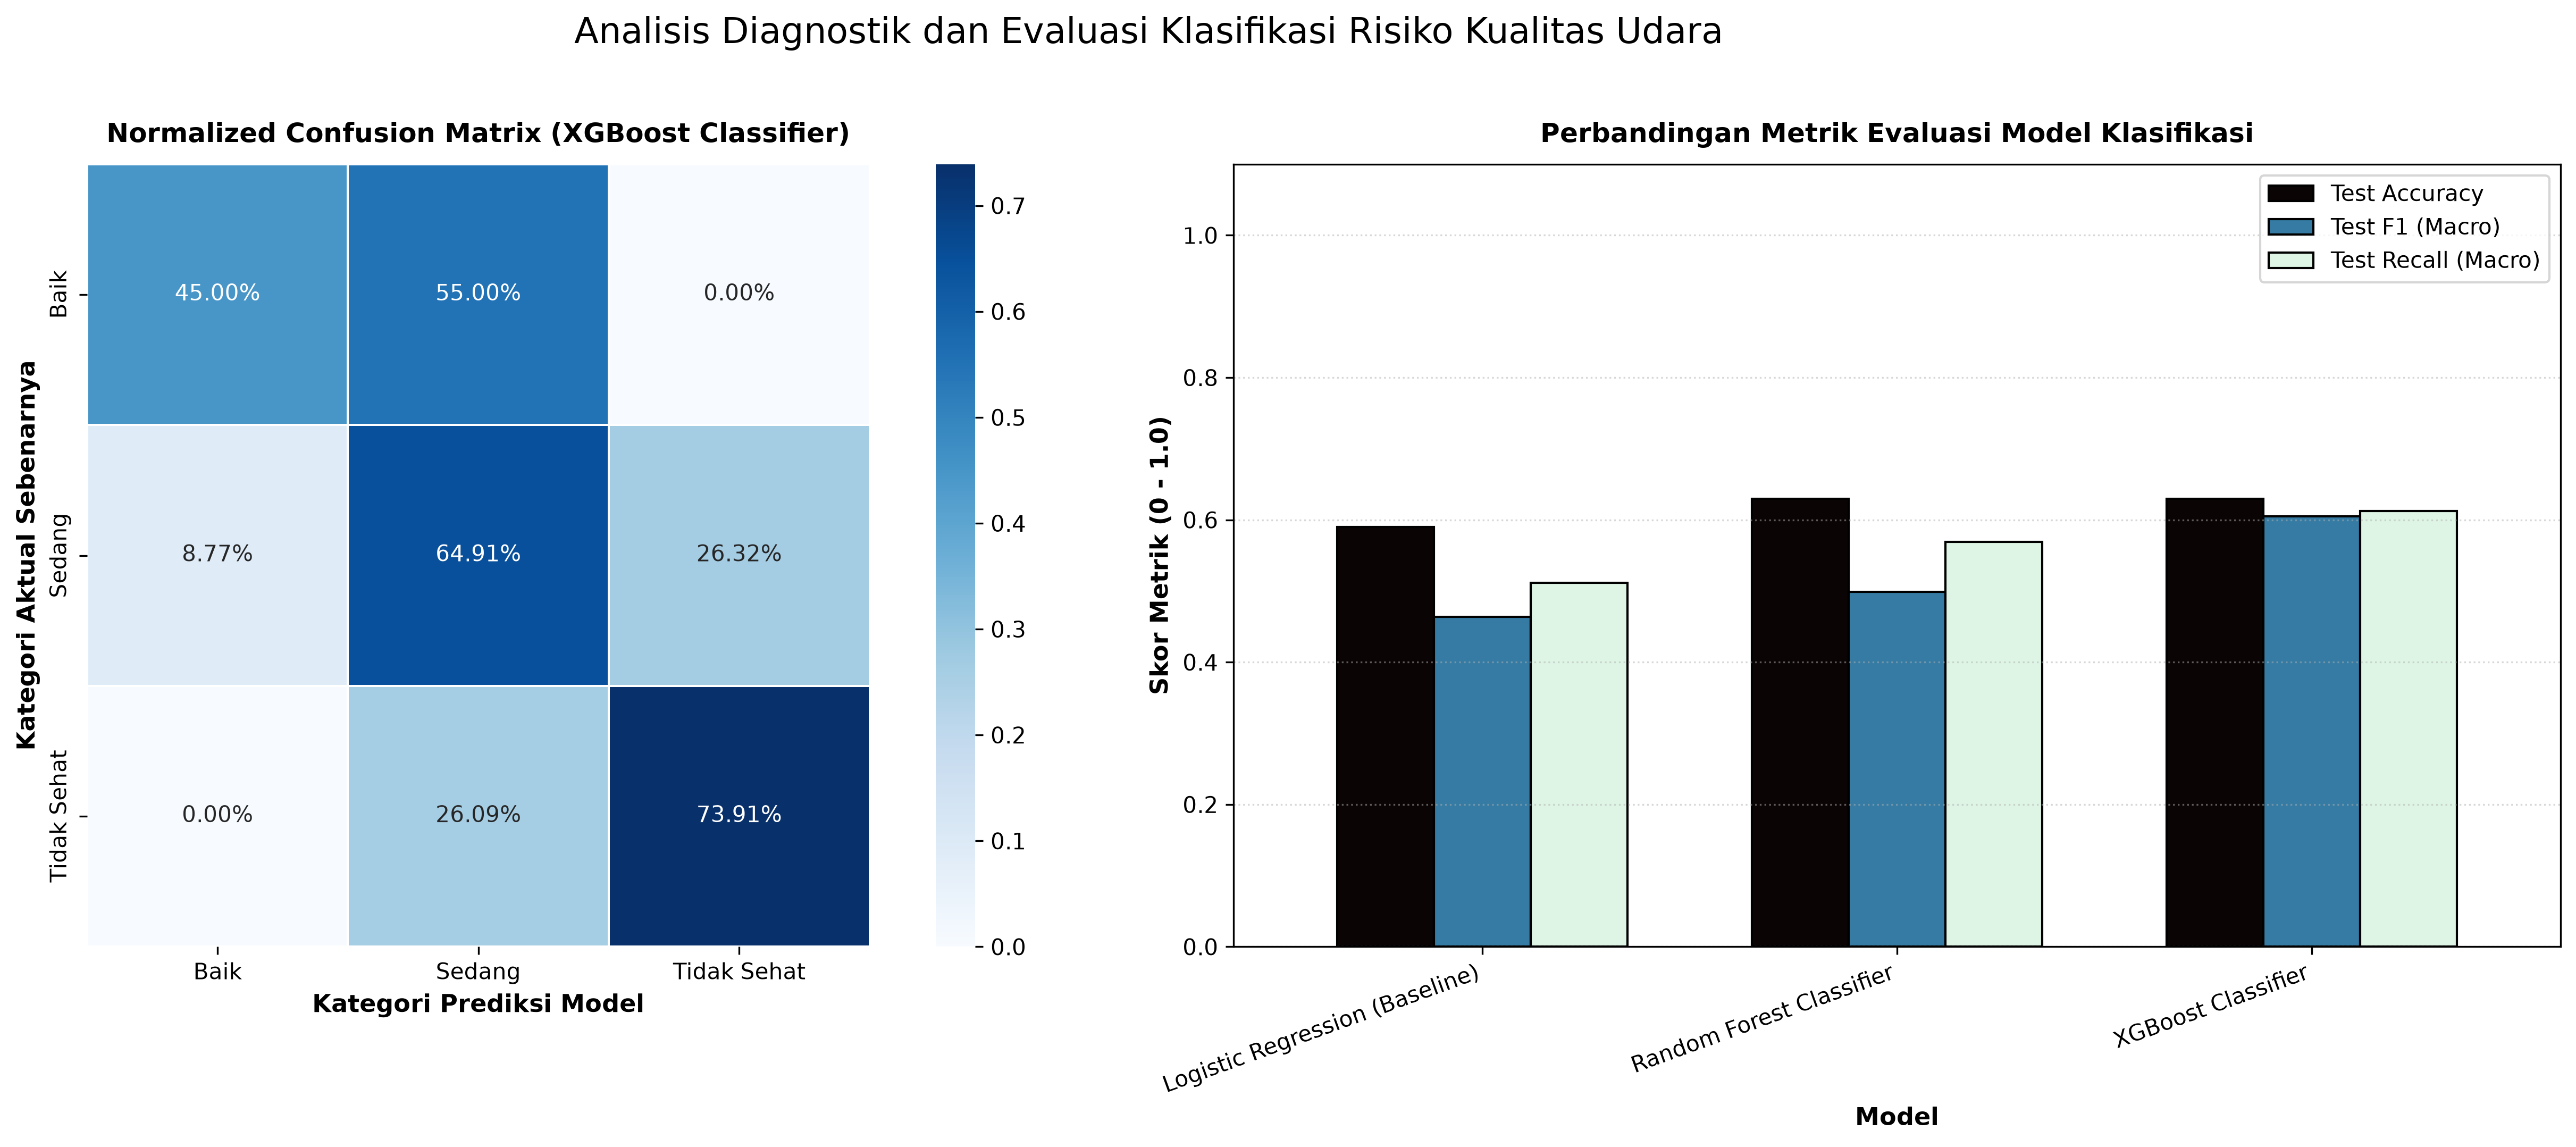

Aset Portofolio Tersimpan: portfolio_assets\07_classification_confusion_matrix.png

=== Laporan Klasifikasi Rinci (Classification Report) ===
              precision    recall  f1-score   support

        Baik       0.64      0.45      0.53        20
      Sedang       0.69      0.65      0.67        57
 Tidak Sehat       0.53      0.74      0.62        23

    accuracy                           0.63       100
   macro avg       0.62      0.61      0.60       100
weighted avg       0.64      0.63      0.63       100



In [14]:
# Sel 14: Visualisasi 7 - Normalized Confusion Matrix Model Terbaik

# Tentukan model klasifikasi terbaik berdasarkan Test F1 (Macro)
best_clf_name = df_results_clf.sort_values(by='Test F1 (Macro)', ascending=False).iloc[0]['Model']
best_pred_clf = predictions_clf[best_clf_name]

cm = confusion_matrix(y_test_clf, best_pred_clf)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Heatmap Confusion Matrix Ter-Normalisasi
sns.heatmap(
    cm_normalized, annot=True, fmt='.2%', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names, ax=ax1,
    cbar=True, square=True, linewidths=0.5
)
ax1.set_title(f"Normalized Confusion Matrix ({best_clf_name})", fontsize=12, pad=10)
ax1.set_xlabel("Kategori Prediksi Model")
ax1.set_ylabel("Kategori Aktual Sebenarnya")

# Perbandingan Metrik Antar-Model (Bar Plot)
df_results_clf.plot(
    x='Model', y=['Test Accuracy', 'Test F1 (Macro)', 'Test Recall (Macro)'],
    kind='bar', ax=ax2, colormap='mako', width=0.7, edgecolor='black'
)
ax2.set_title("Perbandingan Metrik Evaluasi Model Klasifikasi", fontsize=12, pad=10)
ax2.set_ylabel("Skor Metrik (0 - 1.0)")
ax2.set_ylim(0, 1.1)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='right')
ax2.legend(frameon=True, facecolor='white')
ax2.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Analisis Diagnostik dan Evaluasi Klasifikasi Risiko Kualitas Udara", fontsize=16, y=1.02)
plt.tight_layout()

fig7_path = OUTPUT_DIR / '07_classification_confusion_matrix.png'
plt.savefig(fig7_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig7_path}")

print("\n=== Laporan Klasifikasi Rinci (Classification Report) ===")
print(classification_report(y_test_clf, best_pred_clf, target_names=class_names))


---
## Modul 7: Model Interpretability (Explainable AI), Wawasan Bisnis, & Ekspor Portofolio

### Analisis Feature Importance: Penggerak Utama Degradasi Kualitas Udara
Memahami fitur mana yang memiliki kontribusi terbesar terhadap penurunan kualitas udara sangat krusial untuk perumusan kebijakan lingkungan dan mitigasi pencemaran perkotaan.


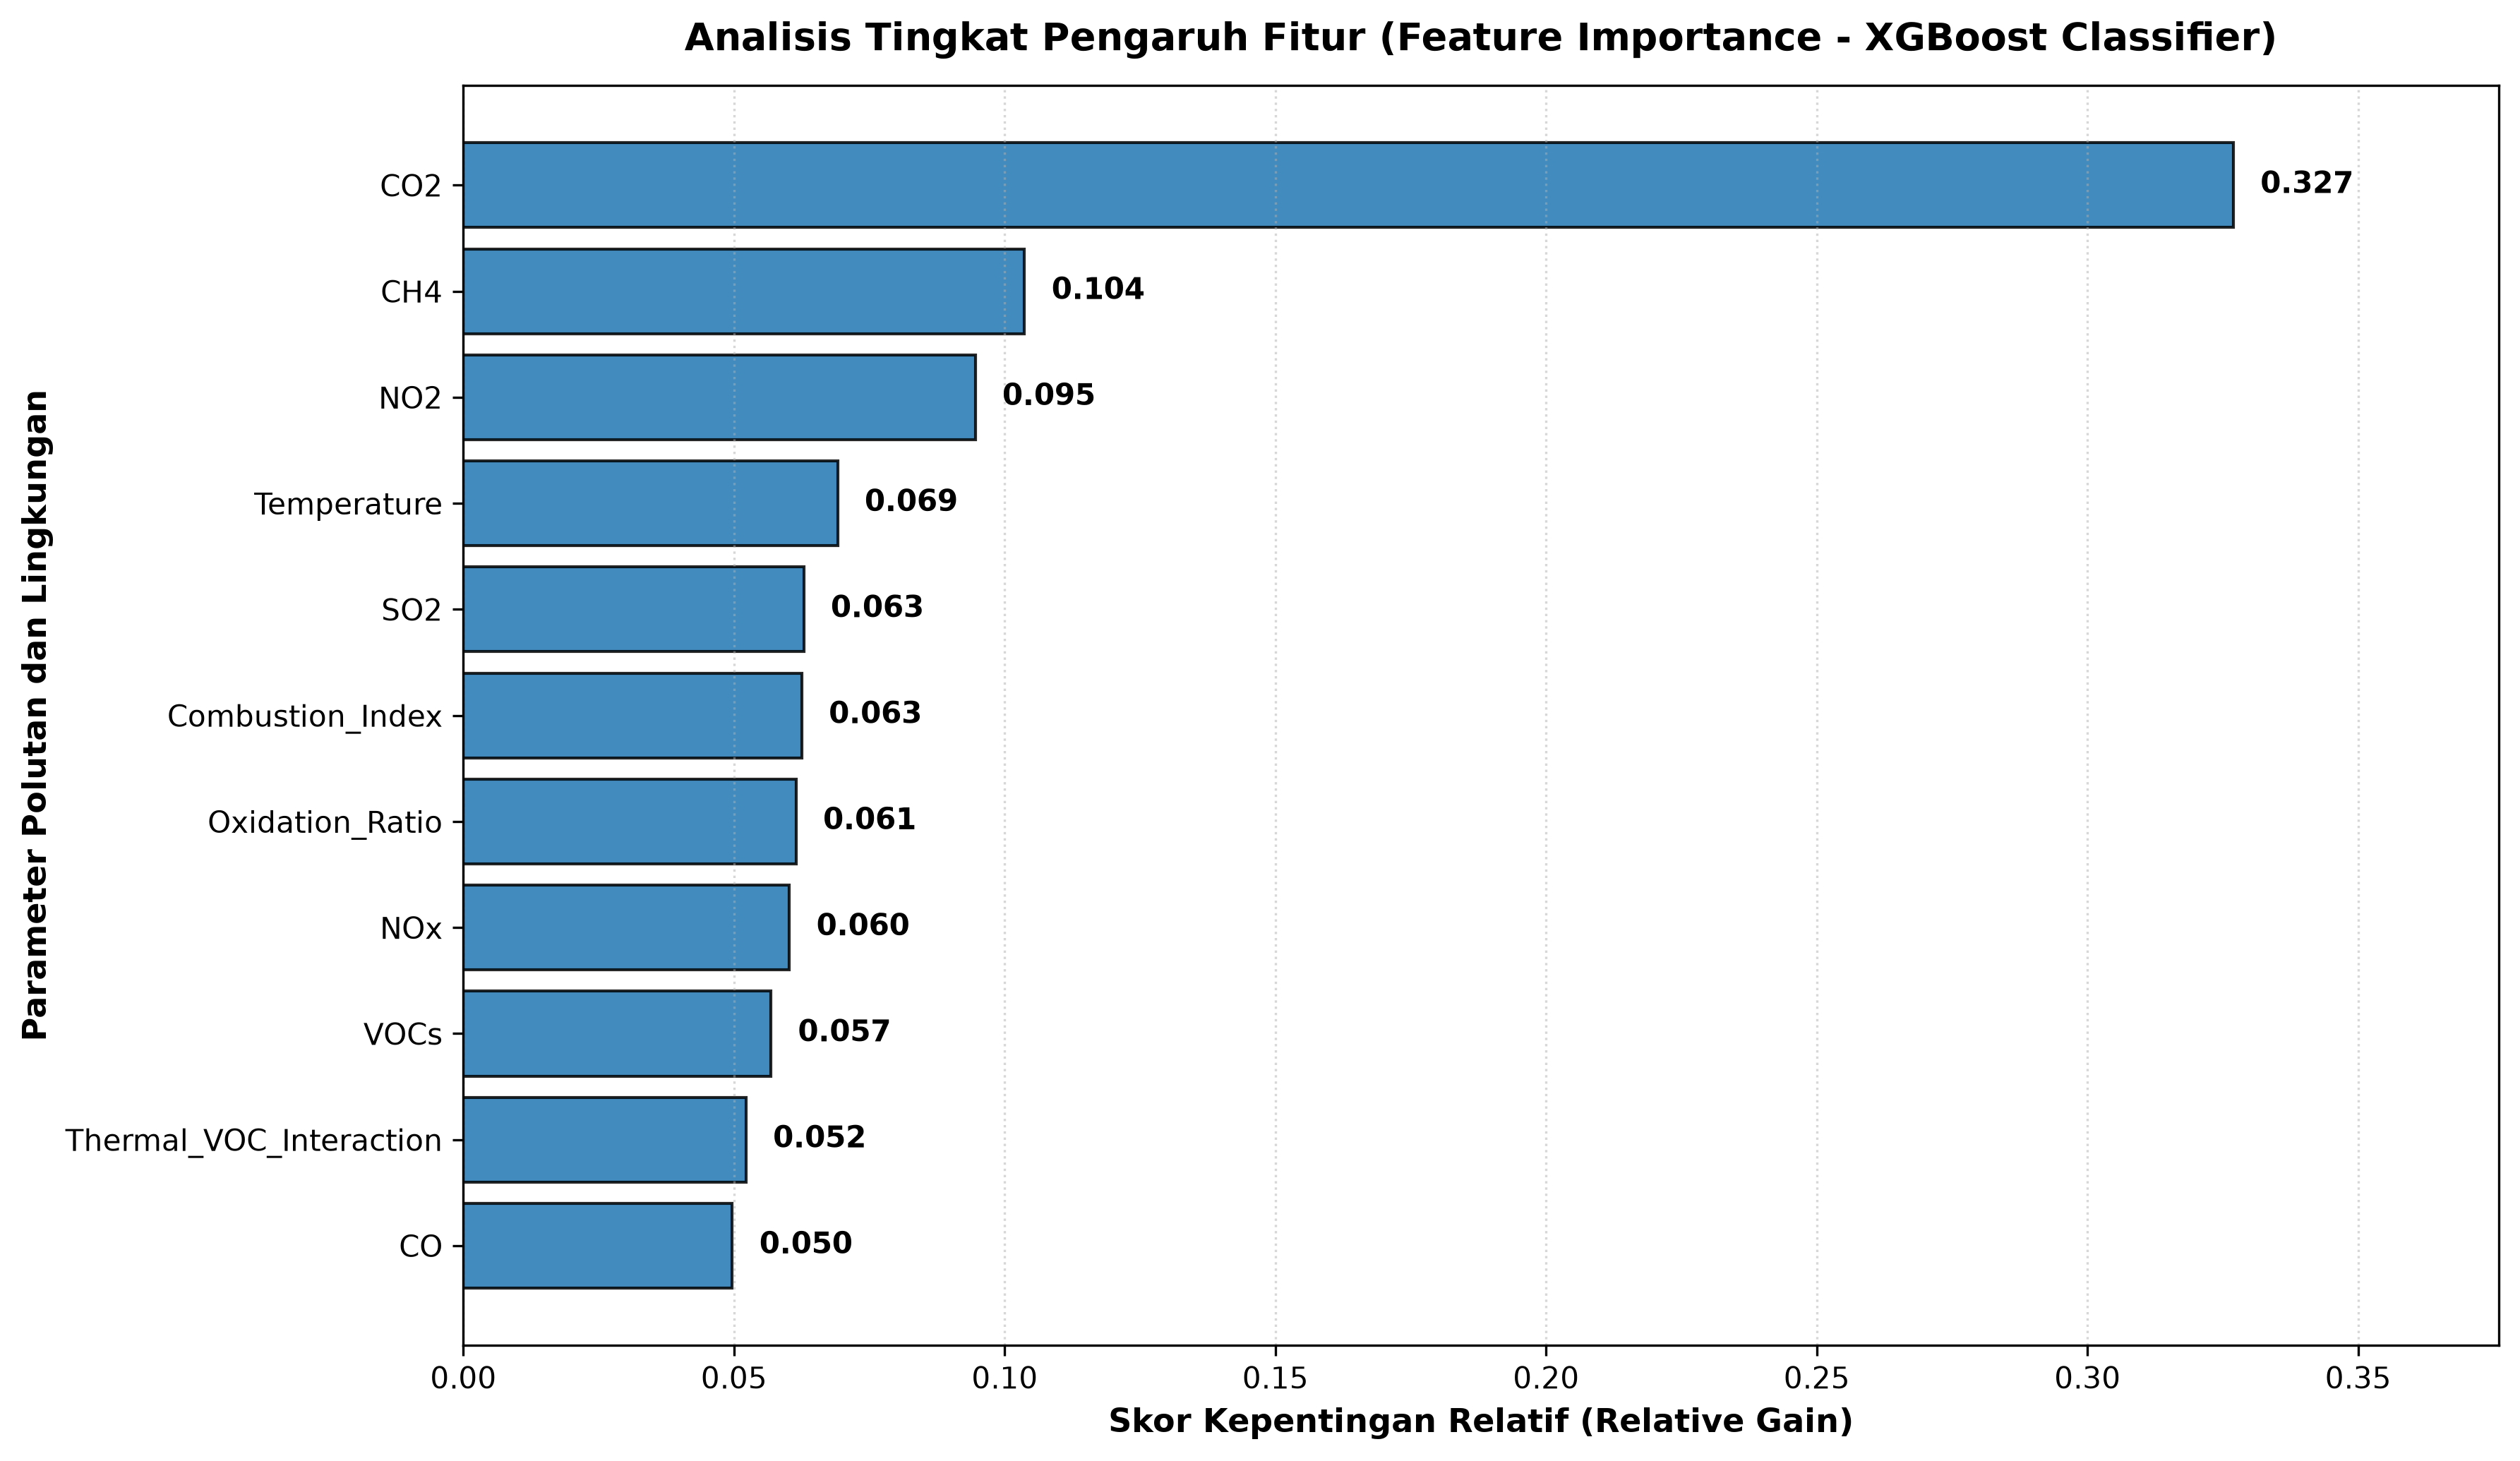

Aset Portofolio Tersimpan: portfolio_assets\08_feature_importance_analysis.png


In [15]:
# Sel 15: Visualisasi 8 - Feature Importance Analisis Model Terbaik

best_xgb_model = fitted_clf_models['XGBoost Classifier']
importances = best_xgb_model.feature_importances_
feat_importance_df = pd.DataFrame({
    'Feature': feature_cols_clf,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(12, 7))
bars = plt.barh(feat_importance_df['Feature'], feat_importance_df['Importance'], color='#1f77b4', edgecolor='black', alpha=0.85)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.005, bar.get_y() + bar.get_height()/2, f"{width:.3f}", va='center', fontsize=10, weight='bold')

plt.title("Analisis Tingkat Pengaruh Fitur (Feature Importance - XGBoost Classifier)", fontsize=13, pad=12)
plt.xlabel("Skor Kepentingan Relatif (Relative Gain)")
plt.ylabel("Parameter Polutan dan Lingkungan")
plt.xlim(0, max(importances) * 1.15)
plt.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()

fig8_path = OUTPUT_DIR / '08_feature_importance_analysis.png'
plt.savefig(fig8_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Aset Portofolio Tersimpan: {fig8_path}")


### Wawasan Sintesis dan Rekomendasi Kebijakan Kualitas Udara

Berdasarkan seluruh hasil audit data, korelasi statistik, pemodelan regresi, dan klasifikasi machine learning:
1. **Dominasi Belerang Dioksida (SO2) dan Oksida Nitrogen (NOx/NO2)**:
   - SO2 dan rasio oksidasi nitrogen muncul sebagai pendorong terkuat memburuknya kualitas udara ke level *Tidak Sehat*. Hal ini mengindikasikan bahwa pembakaran bahan bakar bertaraf industri dan knalpot kendaraan bermotor berbahan bakar fosil merupakan kontributor pencemaran aerosol sekunder terbesar di wilayah perkotaan ini.
2. **Interaksi Termal Lingkungan**:
   - Peningkatan suhu lingkungan terbukti berkorelasi positif dengan eskalasi konsentrasi polutan gas, menunjukkan bahwa kondisi gelombang panas (*heatwave*) dapat memperburuk stagnasi polusi udara perkotaan akibat terhambatnya difusi atmosferik.
3. **Penerapan Sistem Peringatan Dini (Early Warning System)**:
   - Model klasifikasi XGBoost yang dibangun mampu mendeteksi kategori kualitas udara berbahaya hanya dengan memanfaatkan sensor gas tanpa memerlukan pembacaan optik PM2.5 langsung. Pola ini memungkinkan implementasi stasiun pemantau hemat biaya (*cost-effective multi-sensor node*) untuk kota cerdas (*Smart Cities*).

---

### Manifest Aset Visual Portofolio
Seluruh grafik analitis beresolusi tinggi (300 DPI) telah berhasil diekspor secara otomatis ke folder `portfolio_assets/`. File-file ini siap diunggah atau di-screenshot untuk melengkapi studi kasus portofolio di [portfolio.web.id](https://fauziasyabani.portfolio.web.id).


In [16]:
# Sel 16: Verifikasi dan Pembuatan Manifest Ringkasan Aset Portofolio

manifest = []
for file in sorted(OUTPUT_DIR.glob('*.png')):
    file_size_kb = file.stat().st_size / 1024
    manifest.append({
        'Nama File': file.name,
        'Ukuran (KB)': f"{file_size_kb:.2f} KB",
        'Tujuan Portofolio': 'Screenshot Visualisasi Kualitas Tinggi (300 DPI)',
        'Path Lengkap': str(file.resolve())
    })

manifest_df = pd.DataFrame(manifest)
print(f"=== Total {len(manifest)} Aset Portofolio Berhasil Diekspor ke: {OUTPUT_DIR.resolve()} ===")
manifest_df


=== Total 8 Aset Portofolio Berhasil Diekspor ke: D:\Code\air-quality\portfolio_assets ===


,Nama File,Ukuran (KB),Tujuan Portofolio,Path Lengkap
0,01_pollutant_distributions.png,706.80 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\01_pollut...
1,02_multivariate_correlation_matrix.png,455.76 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\02_multiv...
2,03_temperature_impact_analysis.png,1458.24 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\03_temper...
3,04_pm_ratio_analysis.png,573.93 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\04_pm_rat...
4,05_category_pollutant_characteristics.png,205.96 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\05_catego...
5,06_regression_performance_diagnostics.png,486.81 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\06_regres...
6,07_classification_confusion_matrix.png,301.17 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\07_classi...
7,08_feature_importance_analysis.png,203.72 KB,Screenshot Visualisasi Kualitas Tinggi (300 DPI),D:\Code\air-quality\portfolio_assets\08_featur...
